
# GrainSense: Automated Rice Variety Classification for Quality Control

### IT3091 Machine Learning — Group 4 (Agriculture: Rice Cammeo & Osmancik)

The notebook follows CRISP-DM (Lecture 1): **Business Understanding → Data Understanding → Data Preparation → Modelling → Evaluation**.

| Part | Sections | Member |
|---|---|---|
| Business problem, data understanding and EDA | 1–8 | Member 1 |
| Data preprocessing and feature engineering | 9–10 | Member 2 |
| Model training and comparison | 11 | Member 3 |
| Model evaluation, selection and recommendation | 12 | Member 4 |

> KDD and CRISP-DM are iterative: findings at one stage may send the group back to re-think earlier decisions. Any such change is recorded in the decision logs.

## Member 1: Data Understanding & Exploratory Data Analysis (EDA)

Data understanding follows the flow from Lecture 2:

**Business Problem → Collect Dataset → Understand Features → Explore the Data → Identify Problems → Ready for ML**

### How this notebook maps to the assignment marking criteria

| Criterion (marks) | What the rubric asks for | Where it is |
|---|---|---|
| Business problem framing (5) | Stakeholder, decision need, lens, unit of analysis, task/output | Section 1 |
| Workflow diagram & decision log (10) | Coherent workflow; decisions with options, reasons, evidence | Workflow diagram: final report. Decision logs: 8.1, 10 summary, 11.9 |
| Data understanding, EDA, data quality reasoning (10) | Data dictionary, row meaning, variable types, patterns, data issues, how issues affect the task | Sections 3–7 |
| Preprocessing & feature-engineering decisions (15) | Missing values, outliers, duplicates, categories, scaling, imbalance, leakage | Sections 6.1, 9, 10 |
| Model/data-mining strategy & comparison (20) | Baseline and at least three alternatives, justified | Section 11 |
| Evaluation, validation & critical judgement (20) | Metrics, CV, leakage prevention, honest interpretation | Section 12 |
| Recommendation, limitations & stakeholder value (10) | Practical recommendation, limitations, risks, value | Sections 6.2, 12.9 |
| Reproducibility & AI-use transparency (10) | Runs clearly, dataset link/fingerprint, AI-use declared | Sections 2.4, 8. AI-use declaration: final report |

### Lecture references

- **Lecture 1:** CRISP-DM, KDD, supervised learning, dataset terminology
- **Lecture 2:** Data understanding flow, variable types, univariate/bivariate/multivariate EDA, data quality dimensions, outliers, leakage, sampling, modelling assumptions
- **Lecture 3:** Label encoding, scaling, transformation, train-only fitting, Pipeline
- **Lecture 4:** Correlation-based importance (filter method), feature selection, PCA, class imbalance, SMOTE, stratified split



## 1. Business Problem

| Element | Decision |
|---|---|
| Track | Guided Data Track |
| Stakeholder | A rice mill / seed company doing quality control |
| Decision need | Verify rice variety automatically instead of slow, error-prone manual visual sorting, so grains are graded and priced correctly |
| Primary lens | Variety classification |
| Secondary lens | None — primary lens only (optional per the descriptor; see decision D-EDA-8) |
| Learning paradigm | Supervised learning (labelled examples) |
| Task | Binary classification |
| Target variable (label) | `Class` — Cammeo or Osmancik |
| Unit of analysis / row meaning | One row = one rice grain photographed and measured by image processing |
| Output | Predicted variety (Cammeo or Osmancik) with its probability |

*(Lecture 1: supervised learning; Lecture 2: Business Problem is the first step of data understanding.)*


## 2. Collect Dataset
### 2.1 Setup — Google Drive and paths
**Dataset:** Rice (Cammeo and Osmancik), UCI Machine Learning Repository, id 545 — https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik

The dataset is fetched with `ucimlrepo` on the **first run** and saved to Drive as a snapshot CSV.
Later runs, and every teammate, load the same snapshot, so everyone uses identical data and the notebook still runs if the UCI site is down.

In [1]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE_DIR      = '/content/drive/MyDrive/IT3091_Group4' if IN_COLAB else '.'
SNAPSHOT_FILE = 'rice_uci545_snapshot.csv'   # created automatically on first run
FORCE_REFETCH = False                        # True = download from UCI again and overwrite the snapshot

DATA_PATH  = os.path.join(BASE_DIR, SNAPSHOT_FILE)
OUTPUT_DIR = os.path.join(BASE_DIR, 'eda_outputs')
FIG_DIR    = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

print('Snapshot already saved:', os.path.exists(DATA_PATH), '->', DATA_PATH)
print('Outputs will be saved to:', OUTPUT_DIR)

Snapshot already saved: False -> .\rice_uci545_snapshot.csv
Outputs will be saved to: .\eda_outputs


### 2.2 Import libraries

In [2]:
import re, sys, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
PALETTE = {'Cammeo': '#1f77b4', 'Osmancik': '#ff7f0e'}

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=150, bbox_inches='tight')

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 2.2.2 | numpy 1.26.4 | seaborn 0.13.2


### 2.3 Load the dataset

In [3]:
CANON = {
    'area': 'Area', 'perimeter': 'Perimeter',
    'majoraxislength': 'Major_Axis_Length', 'minoraxislength': 'Minor_Axis_Length',
    'majoraxis': 'Major_Axis_Length', 'minoraxis': 'Minor_Axis_Length',
    'eccentricity': 'Eccentricity', 'convexarea': 'Convex_Area',
    'extent': 'Extent', 'class': 'Class',
}
FEATURES = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length',
            'Eccentricity', 'Convex_Area', 'Extent']
TARGET = 'Class'

def fetch_from_uci():
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ucimlrepo'])
        from ucimlrepo import fetch_ucirepo
    rice = fetch_ucirepo(id=545)
    raw = pd.concat([rice.data.features, rice.data.targets], axis=1)
    return raw, rice

uci = None
if os.path.exists(DATA_PATH) and not FORCE_REFETCH:
    df = pd.read_csv(DATA_PATH)
    print('Loaded saved snapshot from Drive.')
else:
    df, uci = fetch_from_uci()
    df.to_csv(DATA_PATH, index=False)
    print('Fetched from UCI (id=545) and saved snapshot to:', DATA_PATH)

df.columns = [CANON.get(re.sub(r'[^a-z]', '', str(c).lower()), c) for c in df.columns]
missing_cols = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_cols:
    raise ValueError(f'Expected columns not found: {missing_cols}. Columns present: {list(df.columns)}')

df[TARGET] = df[TARGET].astype(str).str.strip()
df = df[FEATURES + [TARGET]]

if uci is not None:   # only on the run that fetched from UCI
    print('\nUCI variable information:')
    display(uci.variables)
df.head()

Fetched from UCI (id=545) and saved snapshot to: .\rice_uci545_snapshot.csv

UCI variable information:


,name,role,type,demographic,description,units,missing_values
0,Area,Feature,Integer,None,Returns the number of pixels within the bounda...,px,no
1,Perimeter,Feature,Continuous,None,Calculates the circumference by calculating th...,px,no
2,Major_Axis_Length,Feature,Continuous,None,The longest line that can be drawn on the rice...,None,no
3,Minor_Axis_Length,Feature,Continuous,None,The shortest line that can be drawn on the ric...,None,no
4,Eccentricity,Feature,Continuous,None,"It measures how round the ellipse, which has t...",None,no
5,Convex_Area,Feature,Integer,None,Returns the pixel count of the smallest convex...,None,no
6,Extent,Feature,Continuous,None,Returns the ratio of the region formed by the ...,None,no
7,Class,Target,Binary,None,Cammeo and Osmancik,None,no


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.5790,229.7499,85.0938,0.9289,15617,0.5729,Cammeo
1,14656,494.3110,206.0201,91.7310,0.8954,15072,0.6154,Cammeo
2,14634,501.1220,214.1068,87.7683,0.9121,14954,0.6933,Cammeo
3,13176,458.3430,193.3374,87.4484,0.8919,13368,0.6407,Cammeo
4,14688,507.1670,211.7434,89.3125,0.9067,15262,0.6460,Cammeo


### 2.4 Dataset fingerprint
Record these values in the report. The hashes show every teammate (and the marker) used the same snapshot.

In [4]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()

fingerprint = {
    'source': 'UCI Machine Learning Repository - Rice (Cammeo and Osmancik), id 545, via ucimlrepo',
    'dataset_link': 'https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik',
    'snapshot_file': SNAPSHOT_FILE,
    'snapshot_saved': pd.Timestamp(os.path.getmtime(DATA_PATH), unit='s').strftime('%Y-%m-%d %H:%M UTC'),
    'n_rows': df.shape[0],
    'n_columns': df.shape[1],
    'file_sha256': sha256_file(DATA_PATH),
    'content_sha256': hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest(),
}
for k, v in fingerprint.items():
    print(f'{k:<15}: {v}')

source         : UCI Machine Learning Repository - Rice (Cammeo and Osmancik), id 545, via ucimlrepo
dataset_link   : https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik
snapshot_file  : rice_uci545_snapshot.csv
snapshot_saved : 2026-10-12 13:21 UTC
n_rows         : 3810
n_columns      : 8
file_sha256    : a249b73ce3f4c4185a379866bae69bb9cab28758215b63ddc549cf9e9cb4a8c4
content_sha256 : 79e9bf69541f5c428f675ab282424a765eb91c715177487792f7dd6c5ca0eda4


## 3. Understand Features
### 3.1 Dataset characteristics
Lecture 2 describes a dataset by its **number of samples**, **number of features** and **target variable**.

In [5]:
print(f'Number of samples (instances / records): {df.shape[0]}')
print(f'Number of features (independent variables): {len(FEATURES)}')
print(f'  -> {FEATURES}')
print(f'Target variable (dependent variable / label): {TARGET} -> {sorted(df[TARGET].unique())}')
print('Data type: structured (rows and columns, fixed schema)\n')
df.info()

Number of samples (instances / records): 3810
Number of features (independent variables): 7
  -> ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
Target variable (dependent variable / label): Class -> ['Cammeo', 'Osmancik']
Data type: structured (rows and columns, fixed schema)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   int64  
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   int64  
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 238.3+ KB


### 3.2 Types of variables and data dictionary
Lecture 2 variable types: Numerical, Categorical, Ordinal, Binary, Date-Time, Text.
The measurements come from images of grains, so size features are in **pixels**, not millimetres.

In [6]:
DESCRIPTIONS = {
    'Area': 'Number of pixels inside the grain boundary (grain size).',
    'Perimeter': 'Length of the grain boundary in pixels.',
    'Major_Axis_Length': 'Longest line through the grain (grain length).',
    'Minor_Axis_Length': 'Shortest line through the grain (grain width).',
    'Eccentricity': 'How elongated the grain is: 0 = circle, close to 1 = long and thin.',
    'Convex_Area': 'Pixel count of the smallest convex shape that encloses the grain.',
    'Extent': 'Grain area divided by the area of its bounding box.',
    'Class': 'Rice variety: Cammeo or Osmancik (the value to predict).',
}
UNITS = {'Area': 'pixels', 'Perimeter': 'pixels', 'Major_Axis_Length': 'pixels',
         'Minor_Axis_Length': 'pixels', 'Eccentricity': 'ratio 0-1', 'Convex_Area': 'pixels',
         'Extent': 'ratio 0-1', 'Class': '-'}

rows = []
for c in FEATURES + [TARGET]:
    s = df[c]
    is_num = c != TARGET
    rows.append({
        'Variable': c,
        'Role': 'Target (dependent)' if c == TARGET else 'Feature (independent)',
        'Variable type': 'Numerical' if is_num else 'Binary',
        'Unit': UNITS[c],
        'Pandas dtype': str(s.dtype),
        'Missing': int(s.isna().sum()),
        'Unique values': int(s.nunique()),
        'Min': round(s.min(), 4) if is_num else '-',
        'Max': round(s.max(), 4) if is_num else '-',
        'Description': DESCRIPTIONS[c],
    })
data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv(os.path.join(OUTPUT_DIR, 'data_dictionary.csv'), index=False)
display(data_dictionary)

type_counts = data_dictionary['Variable type'].value_counts()
for t in ['Numerical', 'Categorical', 'Ordinal', 'Binary', 'Date-Time', 'Text']:
    print(f'{t:<12}: {type_counts.get(t, 0)}')

,Variable,Role,Variable type,Unit,Pandas dtype,Missing,Unique values,Min,Max,Description
0,Area,Feature (independent),Numerical,pixels,int64,0,2828,7551,18913,Number of pixels inside the grain boundary (gr...
1,Perimeter,Feature (independent),Numerical,pixels,float64,0,3738,359.1000,548.4460,Length of the grain boundary in pixels.
2,Major_Axis_Length,Feature (independent),Numerical,pixels,float64,0,3808,145.2645,239.0105,Longest line through the grain (grain length).
3,Minor_Axis_Length,Feature (independent),Numerical,pixels,float64,0,3804,59.5324,107.5425,Shortest line through the grain (grain width).
4,Eccentricity,Feature (independent),Numerical,ratio 0-1,float64,0,3803,0.7772,0.9480,"How elongated the grain is: 0 = circle, close ..."
5,Convex_Area,Feature (independent),Numerical,pixels,int64,0,2857,7723,19099,Pixel count of the smallest convex shape that ...
6,Extent,Feature (independent),Numerical,ratio 0-1,float64,0,3804,0.4974,0.8610,Grain area divided by the area of its bounding...
7,Class,Target (dependent),Binary,-,object,0,2,-,-,Rice variety: Cammeo or Osmancik (the value to...


Numerical   : 7
Categorical : 0
Ordinal     : 0
Binary      : 1
Date-Time   : 0
Text        : 0


**Observations — Understand Features**
- 3,810 samples, 7 features, 1 target. Every row is one grain, so there is no identifier column that could leak information.
- All 7 features are **Numerical** and the target is **Binary**. There are no Categorical, Ordinal, Date-Time or Text variables.
- **Effect on the task:** no one-hot or ordinal encoding is needed; only the target needs label encoding (Lecture 3). Size features are in pixels, so they depend on the camera setup.

## 4. Explore the Data (EDA)
EDA flow from Lecture 2: **Raw Dataset → Statistical Summary → Data Visualization → Pattern Discovery & Issue Detection → Better Understanding**

> This EDA is **descriptive only**: it summarises and plots the data but does not fit or change anything.
> All preprocessing (scaling, transformation, feature selection) will be fitted on the training set only, after the split (Lectures 2–3, train-only fitting).

### 4.1 Statistical summary (univariate)
Central tendency (mean, median, mode) and variability (variance, standard deviation, range), plus skewness.

In [7]:
X = df[FEATURES]
stat_summary = pd.DataFrame({
    'mean': X.mean(),
    'median': X.median(),
    'mode': X.mode().iloc[0],
    'variance': X.var(),
    'std': X.std(),
    'min': X.min(),
    'max': X.max(),
    'range': X.max() - X.min(),
    'skewness': X.skew(),
})
stat_summary.to_csv(os.path.join(OUTPUT_DIR, 'statistical_summary.csv'))
display(stat_summary)
print('Note: the features are continuous measurements, so the mode is less informative than the mean and median.')

print('\nSummary by variety:')
display(df.groupby(TARGET)[FEATURES].agg(['mean', 'median', 'std']).T)

,mean,median,mode,variance,std,min,max,range,skewness
Area,"12,667.7276","12,421.5000","11,422.0000","3,001,097.8690","1,732.3677","7,551.0000","18,913.0000","11,362.0000",0.3252
Perimeter,454.2392,448.8525,432.2980,"1,267.1522",35.5971,359.1000,548.4460,189.3460,0.2214
Major_Axis_Length,188.7762,185.8101,184.8757,304.4564,17.4487,145.2645,239.0105,93.7460,0.2602
Minor_Axis_Length,86.3138,86.4346,86.2791,32.8308,5.7298,59.5324,107.5425,48.0100,-0.1349
Eccentricity,0.8869,0.8891,0.8718,0.0004,0.0208,0.7772,0.9480,0.1708,-0.4492
Convex_Area,"12,952.4969","12,706.5000","11,132.0000","3,157,629.6383","1,776.9720","7,723.0000","19,099.0000","11,376.0000",0.3198
Extent,0.6619,0.6454,0.5882,0.0060,0.0772,0.4974,0.8610,0.3636,0.3438


Note: the features are continuous measurements, so the mode is less informative than the mean and median.

Summary by variety:


Class                         Cammeo    Osmancik
Area              mean   14,162.8920 11,549.7835
                  median 14,212.0000 11,552.5000
                  std     1,286.7705  1,041.9086
Perimeter         mean      487.4389    429.4155
                  median    488.1795    429.2395
                  std        22.1815     20.1544
Major_Axis_Length mean      205.4786    176.2878
                  median    205.7167    175.6654
                  std        10.3339      9.3624
Minor_Axis_Length mean       88.7675     84.4790
                  median     88.8309     84.6335
                  std         5.3502      5.3027
Eccentricity      mean        0.9010      0.8763
                  median      0.9018      0.8762
                  std         0.0134      0.0190
Convex_Area       mean   14,494.4270 11,799.5858
                  median 14,536.5000 11,813.5000
                  std     1,309.4187  1,062.8043
Extent            mean        0.6514      0.6698
                  median      0.6344      0.6527
                  std         0.0822      0.0723

**Observations — Statistical summary**
- **Central tendency:** for every feature the mean and median are close, and all skewness values lie between about −0.45 and 0.34, so the distributions are roughly symmetric.
- **Variability:** the scales differ enormously — Area has a variance of about 3,000,000 while Eccentricity has about 0.0004.
- **By variety:** Cammeo grains are larger on every size feature (mean Area ≈ 14,163 vs 11,550 pixels; mean Major Axis Length ≈ 205.5 vs 176.3). Extent is slightly higher for Osmancik (≈ 0.670 vs 0.651).
- **Effect on the task:** no log/square-root/Box-Cox transformation is needed (Lecture 3). Scaling is needed for Logistic Regression, SVM and KNN, but not for tree-based models.

### 4.2 Univariate analysis — histograms
Shape of each distribution. The red line is the mean and the green line is the median; a gap between them indicates skew.

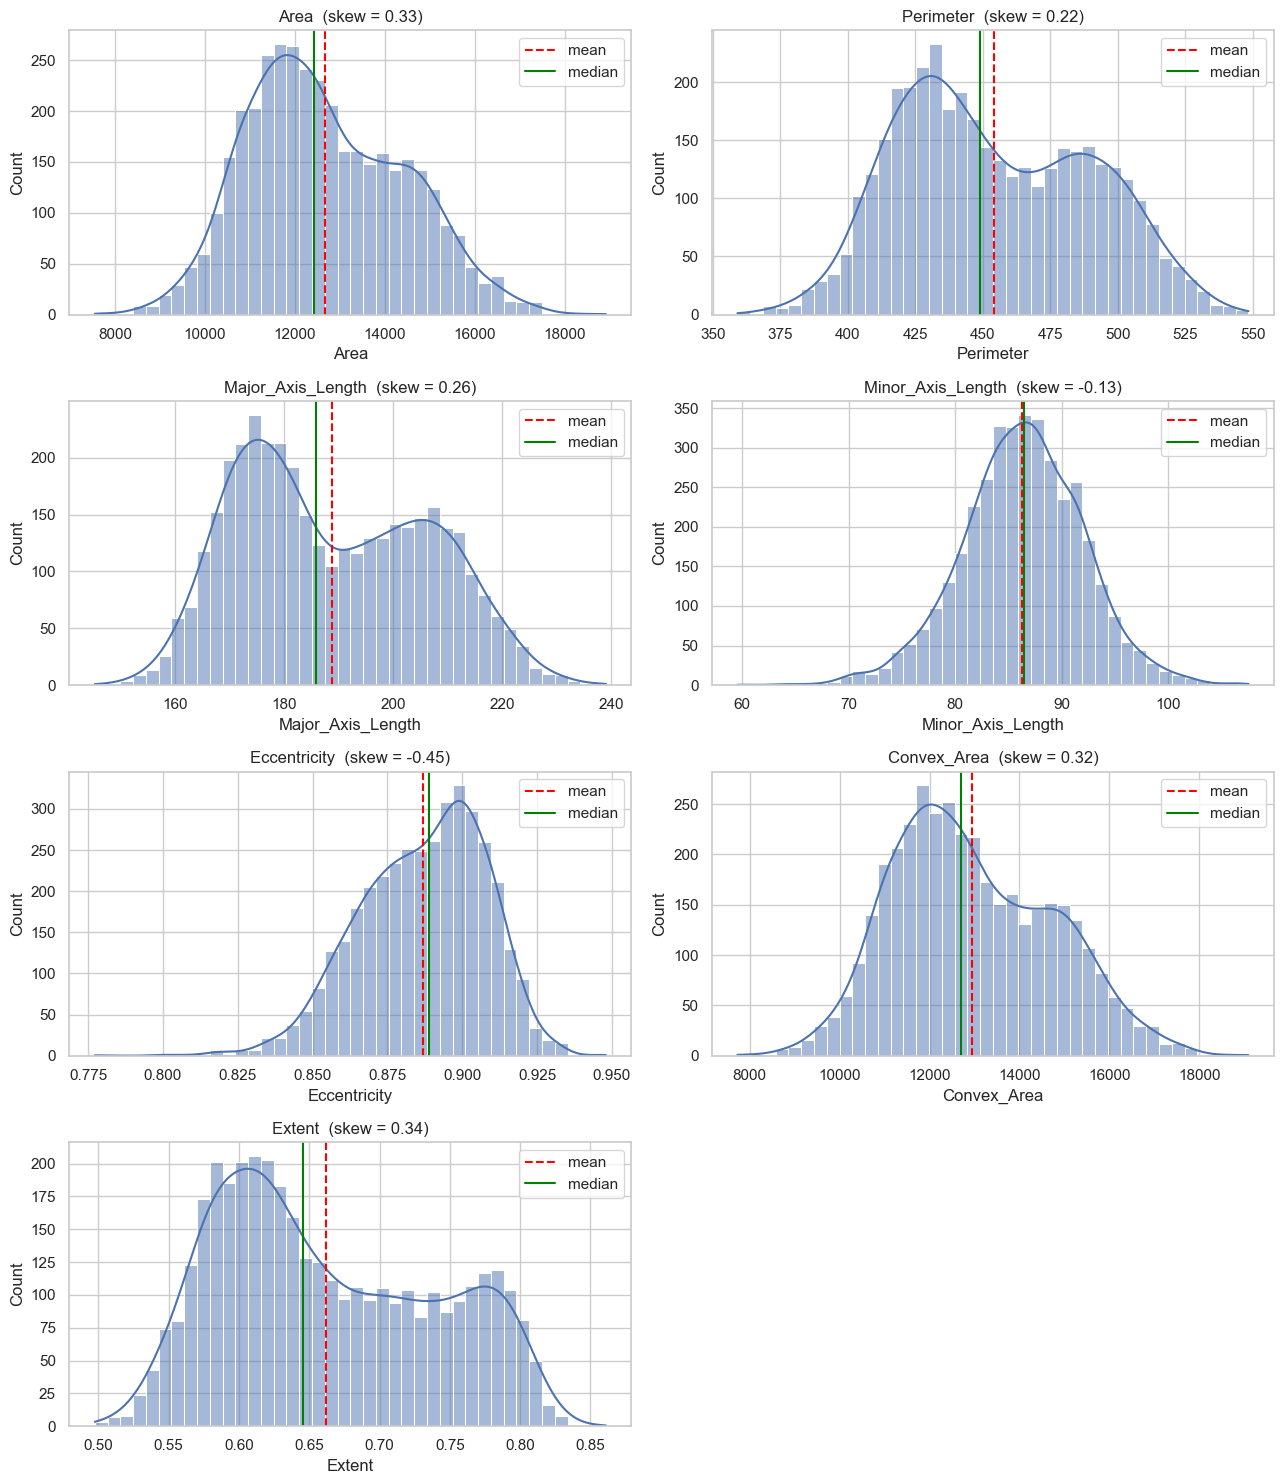

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for ax, f in zip(axes.flat, FEATURES):
    sns.histplot(df[f], bins=40, kde=True, color='#4c72b0', ax=ax)
    ax.axvline(df[f].mean(), color='red', ls='--', label='mean')
    ax.axvline(df[f].median(), color='green', ls='-', label='median')
    ax.set_title(f'{f}  (skew = {df[f].skew():.2f})')
    ax.legend()
axes.flat[-1].axis('off')
plt.tight_layout()
savefig('01_histograms')
plt.show()

### 4.3 Univariate analysis — boxplots (IQR method)
Points beyond the whiskers (1.5 × IQR from the box) are potential outliers.

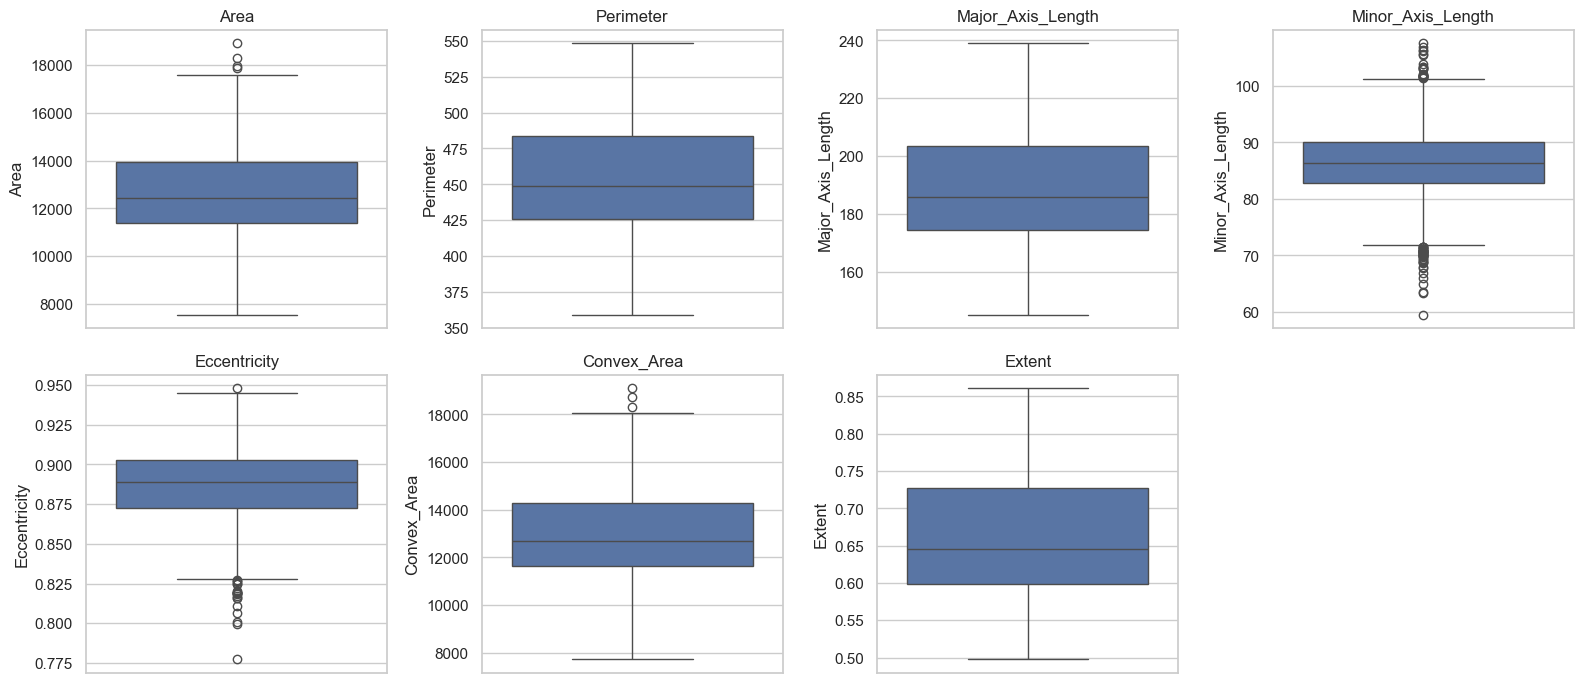

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.flat, FEATURES):
    sns.boxplot(y=df[f], color='#4c72b0', ax=ax)
    ax.set_title(f)
axes.flat[-1].axis('off')
plt.tight_layout()
savefig('02_boxplots')
plt.show()

### 4.4 Bivariate analysis — group comparison by variety
How each feature differs between Cammeo and Osmancik. Clear separation means the feature is useful for classification; overlap means it is harder.

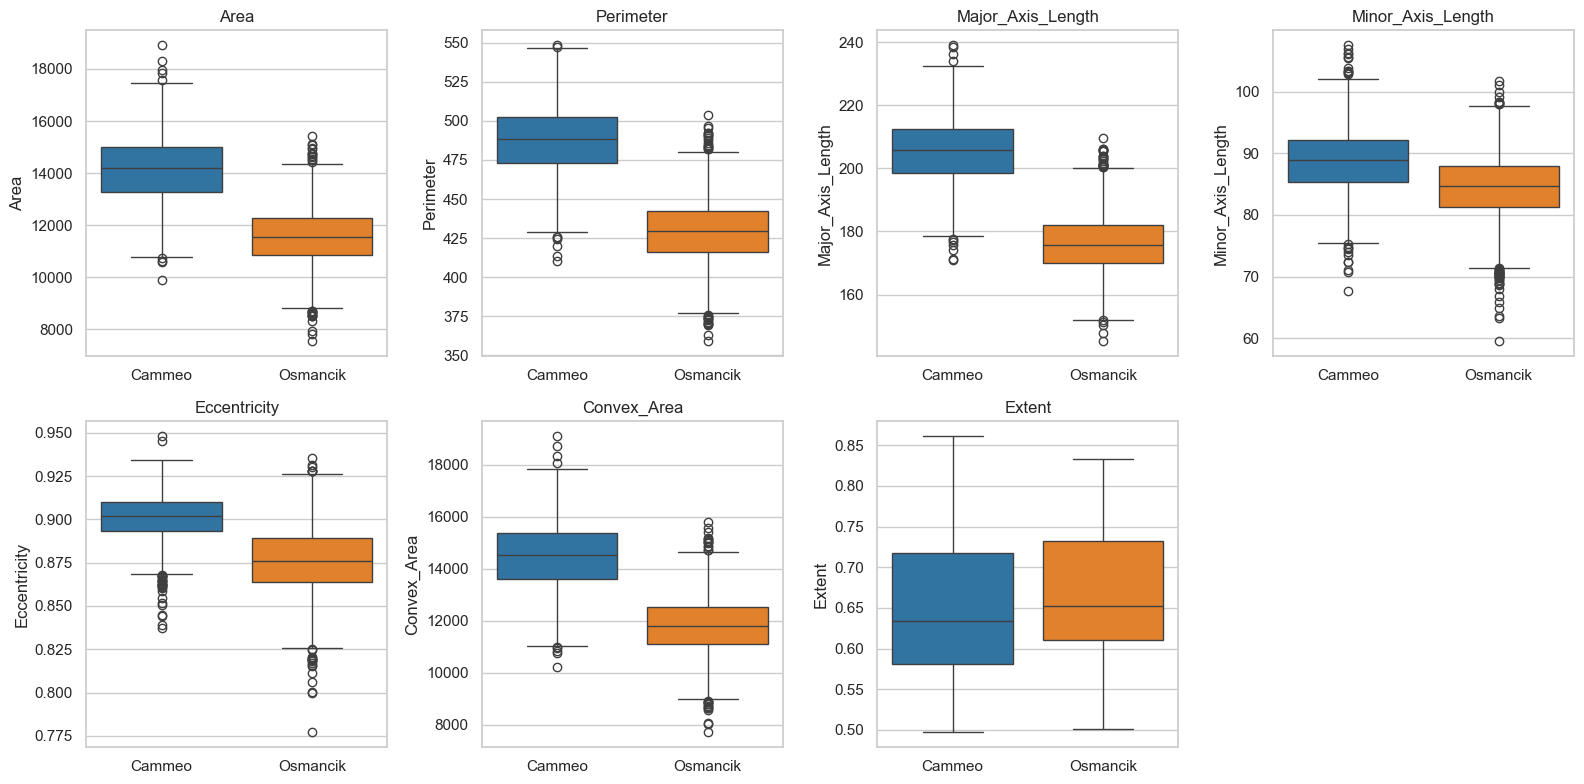

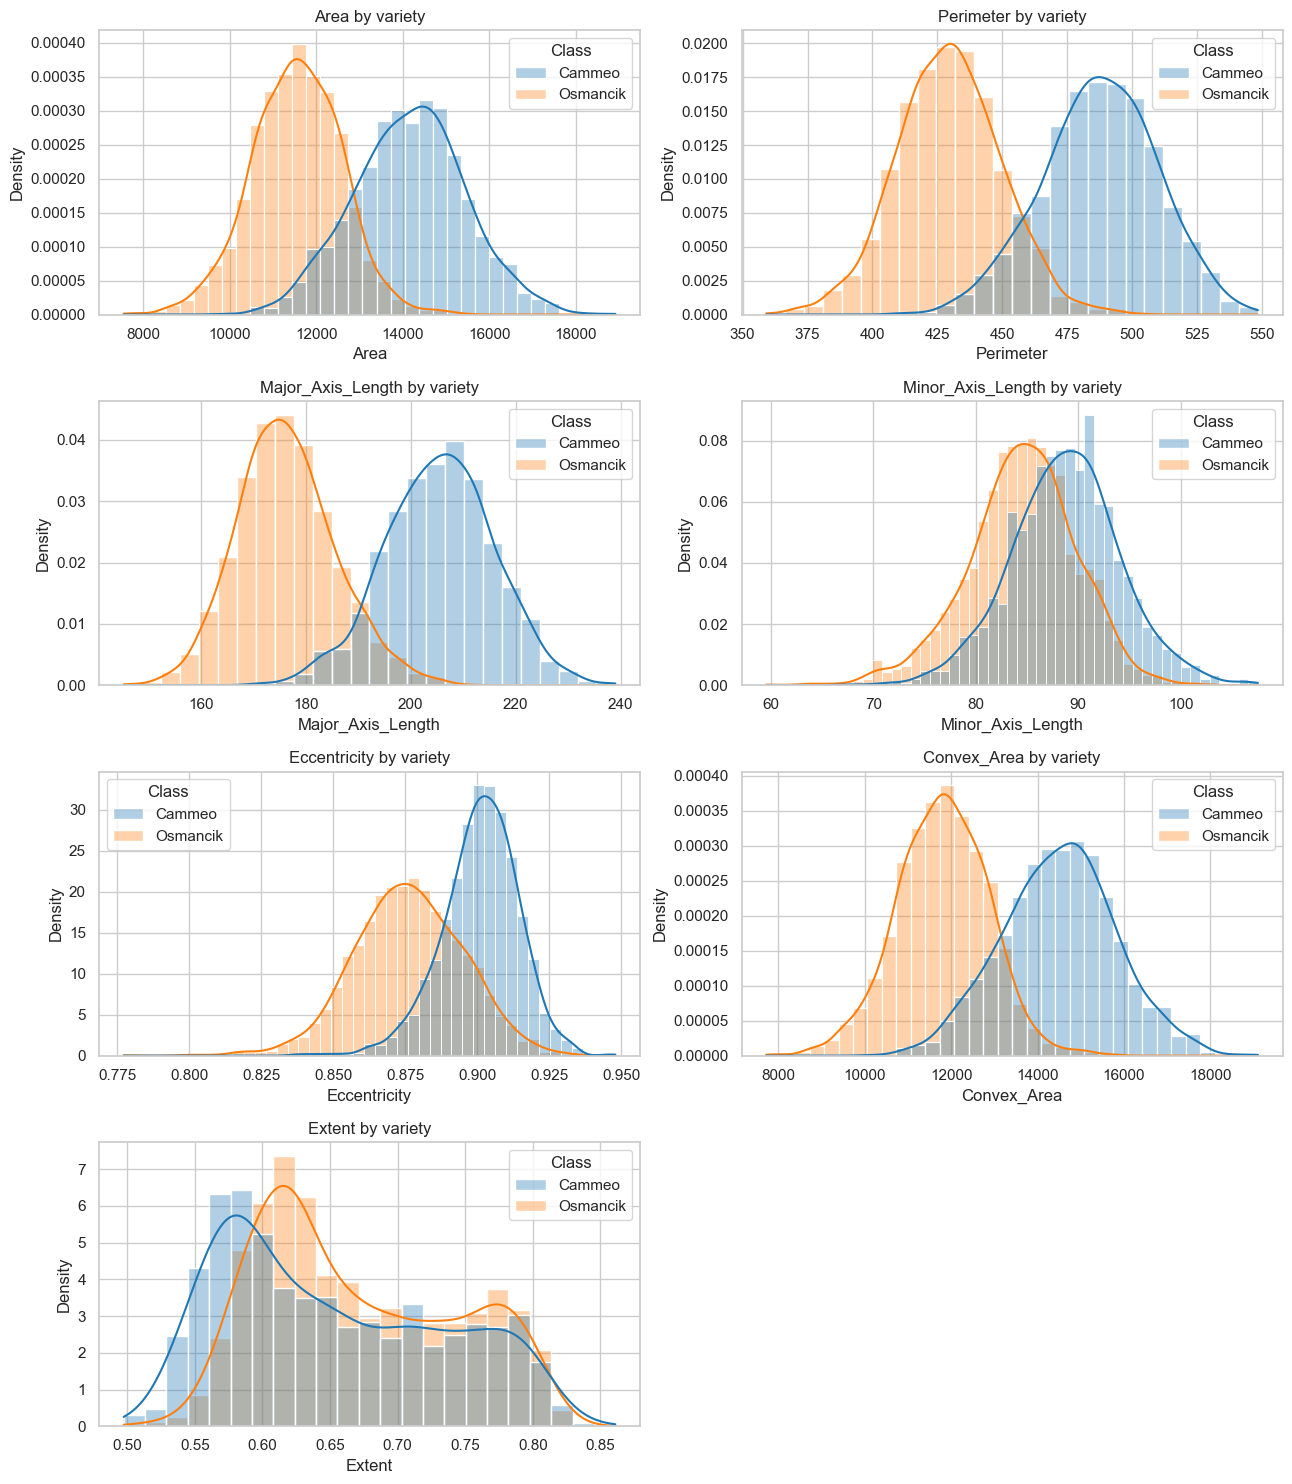

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, f in zip(axes.flat, FEATURES):
    sns.boxplot(data=df, x=TARGET, y=f, hue=TARGET, palette=PALETTE, legend=False, ax=ax)
    ax.set_title(f); ax.set_xlabel('')
axes.flat[-1].axis('off')
plt.tight_layout()
savefig('03_group_comparison_boxplots')
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for ax, f in zip(axes.flat, FEATURES):
    sns.histplot(data=df, x=f, hue=TARGET, kde=True, stat='density', common_norm=False,
                 palette=PALETTE, alpha=0.35, ax=ax)
    ax.set_title(f'{f} by variety')
axes.flat[-1].axis('off')
plt.tight_layout()
savefig('04_group_comparison_histograms')
plt.show()

**Observations — Group comparison**
- Size features (Area, Perimeter, Major Axis Length, Convex Area) show a clear gap between the varieties: for Major Axis Length the difference in means (≈ 29) is about three times the within-variety standard deviation (≈ 10).
- Minor Axis Length (mean difference ≈ 4.3, std ≈ 5.3) and especially Extent (difference ≈ 0.02, std ≈ 0.08) overlap heavily between the varieties.
- **Effect on the task:** grain *length* separates the varieties much better than grain *width* or *Extent*. The overlap means some grains will be hard to classify, so perfect accuracy should not be expected.

### 4.5 Bivariate analysis — scatter plots

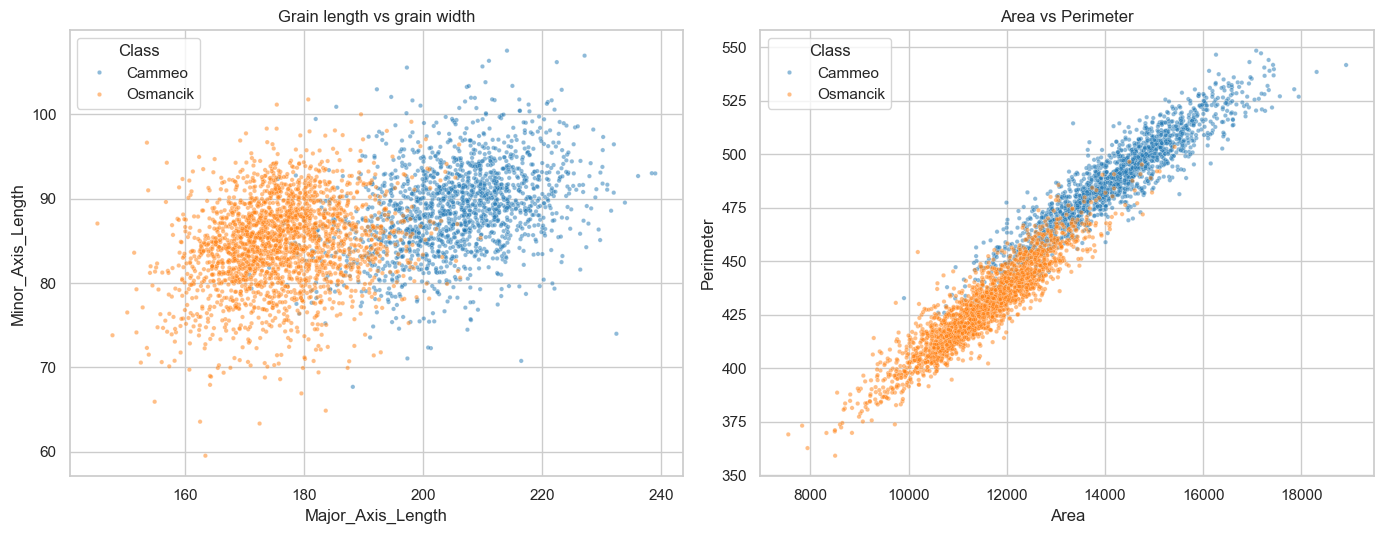

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df, x='Major_Axis_Length', y='Minor_Axis_Length', hue=TARGET,
                palette=PALETTE, s=10, alpha=0.5, ax=axes[0])
axes[0].set_title('Grain length vs grain width')
sns.scatterplot(data=df, x='Area', y='Perimeter', hue=TARGET,
                palette=PALETTE, s=10, alpha=0.5, ax=axes[1])
axes[1].set_title('Area vs Perimeter')
plt.tight_layout()
savefig('05_scatter_plots')
plt.show()


### 4.6 Correlation of each feature with the target

The target is label-encoded (Lecture 3: binary → label encoding): **Cammeo = 1, Osmancik = 0**.

This is **correlation-based importance**, a *filter method* (Lecture 4): fast and model-free, but it only detects linear relationships.

It gives a first ranking to support feature selection; the preprocessing teammate compares it with tree-based importance in Section 10.4.


,Pearson r with target,|r|
Major_Axis_Length,0.8278,0.8278
Perimeter,0.8066,0.8066
Convex_Area,0.7504,0.7504
Area,0.7464,0.7464
Eccentricity,0.5889,0.5889
Minor_Axis_Length,0.3704,0.3704
Extent,-0.1177,0.1177


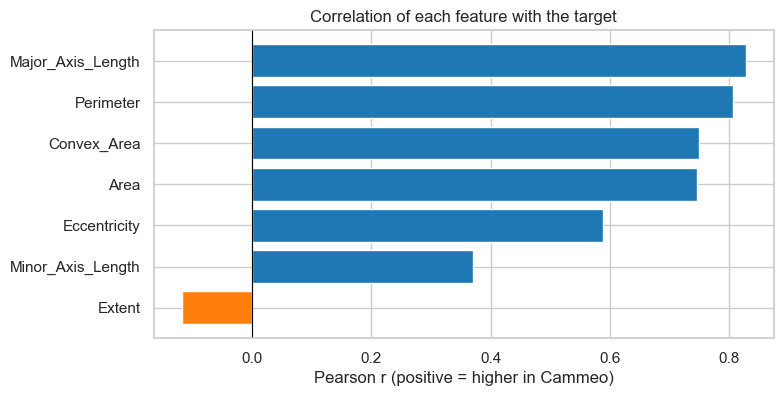

In [12]:
y_encoded = (df[TARGET] == 'Cammeo').astype(int)
corr_target = df[FEATURES].corrwith(y_encoded).to_frame('Pearson r with target')
corr_target['|r|'] = corr_target['Pearson r with target'].abs()
corr_target = corr_target.sort_values('|r|', ascending=False)
corr_target.to_csv(os.path.join(OUTPUT_DIR, 'correlation_with_target.csv'))
display(corr_target)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#1f77b4' if v > 0 else '#ff7f0e' for v in corr_target['Pearson r with target']]
ax.barh(corr_target.index, corr_target['Pearson r with target'], color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.invert_yaxis()
ax.set_xlabel('Pearson r (positive = higher in Cammeo)')
ax.set_title('Correlation of each feature with the target')
savefig('06_correlation_with_target')
plt.show()


**Observations — Correlation with the target**

- Ranking: Major Axis Length (r ≈ 0.83) > Perimeter (0.81) > Convex Area (0.75) ≈ Area (0.75) > Eccentricity (0.59) > Minor Axis Length (0.37) > Extent (−0.12).
- Positive r means the feature is higher in Cammeo. Extent is the only feature slightly higher in Osmancik and is almost unrelated to the target.
- **Effect on the task:** grain length and perimeter are the most useful single measurements, while Extent adds little. This is a *filter method* that only sees linear relationships, so the preprocessing stage checks it against tree-based importance (Lecture 4) before selecting features.


### 4.7 Multivariate analysis — correlation heatmap
Strongly correlated feature pairs (|r| ≥ 0.9) carry overlapping information and are **redundant features** (Lecture 4).

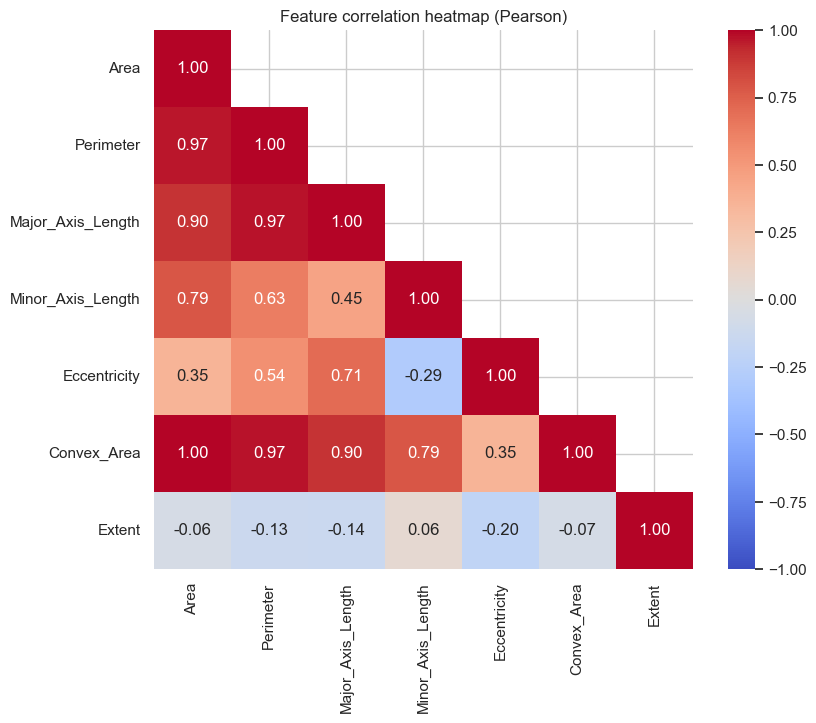

Redundant feature pairs (|r| >= 0.9): 6


,Feature A,Feature B,r
4,Area,Convex_Area,0.9989
6,Perimeter,Major_Axis_Length,0.9719
9,Perimeter,Convex_Area,0.9699
0,Area,Perimeter,0.9665
13,Major_Axis_Length,Convex_Area,0.9034
1,Area,Major_Axis_Length,0.9030


In [13]:
corr = df[FEATURES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Feature correlation heatmap (Pearson)')
savefig('07_correlation_heatmap')
plt.show()

pairs = [{'Feature A': a, 'Feature B': b, 'r': corr.loc[a, b]}
         for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]]
pairs = pd.DataFrame(pairs)
redundant_pairs = pairs[pairs['r'].abs() >= 0.9].sort_values('r', key=abs, ascending=False)
print(f'Redundant feature pairs (|r| >= 0.9): {len(redundant_pairs)}')
display(redundant_pairs)

**Observations — Correlation heatmap**
- 6 feature pairs have |r| ≥ 0.9. Area and Convex Area are almost identical (r ≈ 0.999); Perimeter, Major Axis Length, Area and Convex Area all measure overall grain size.
- **Effect on the task:** these are **redundant features** (Lecture 4). Keeping all of them can make Logistic Regression coefficients unstable and split importance between correlated features. The preprocessing teammate should consider feature selection or PCA.

### 4.8 Multivariate analysis — pair plot

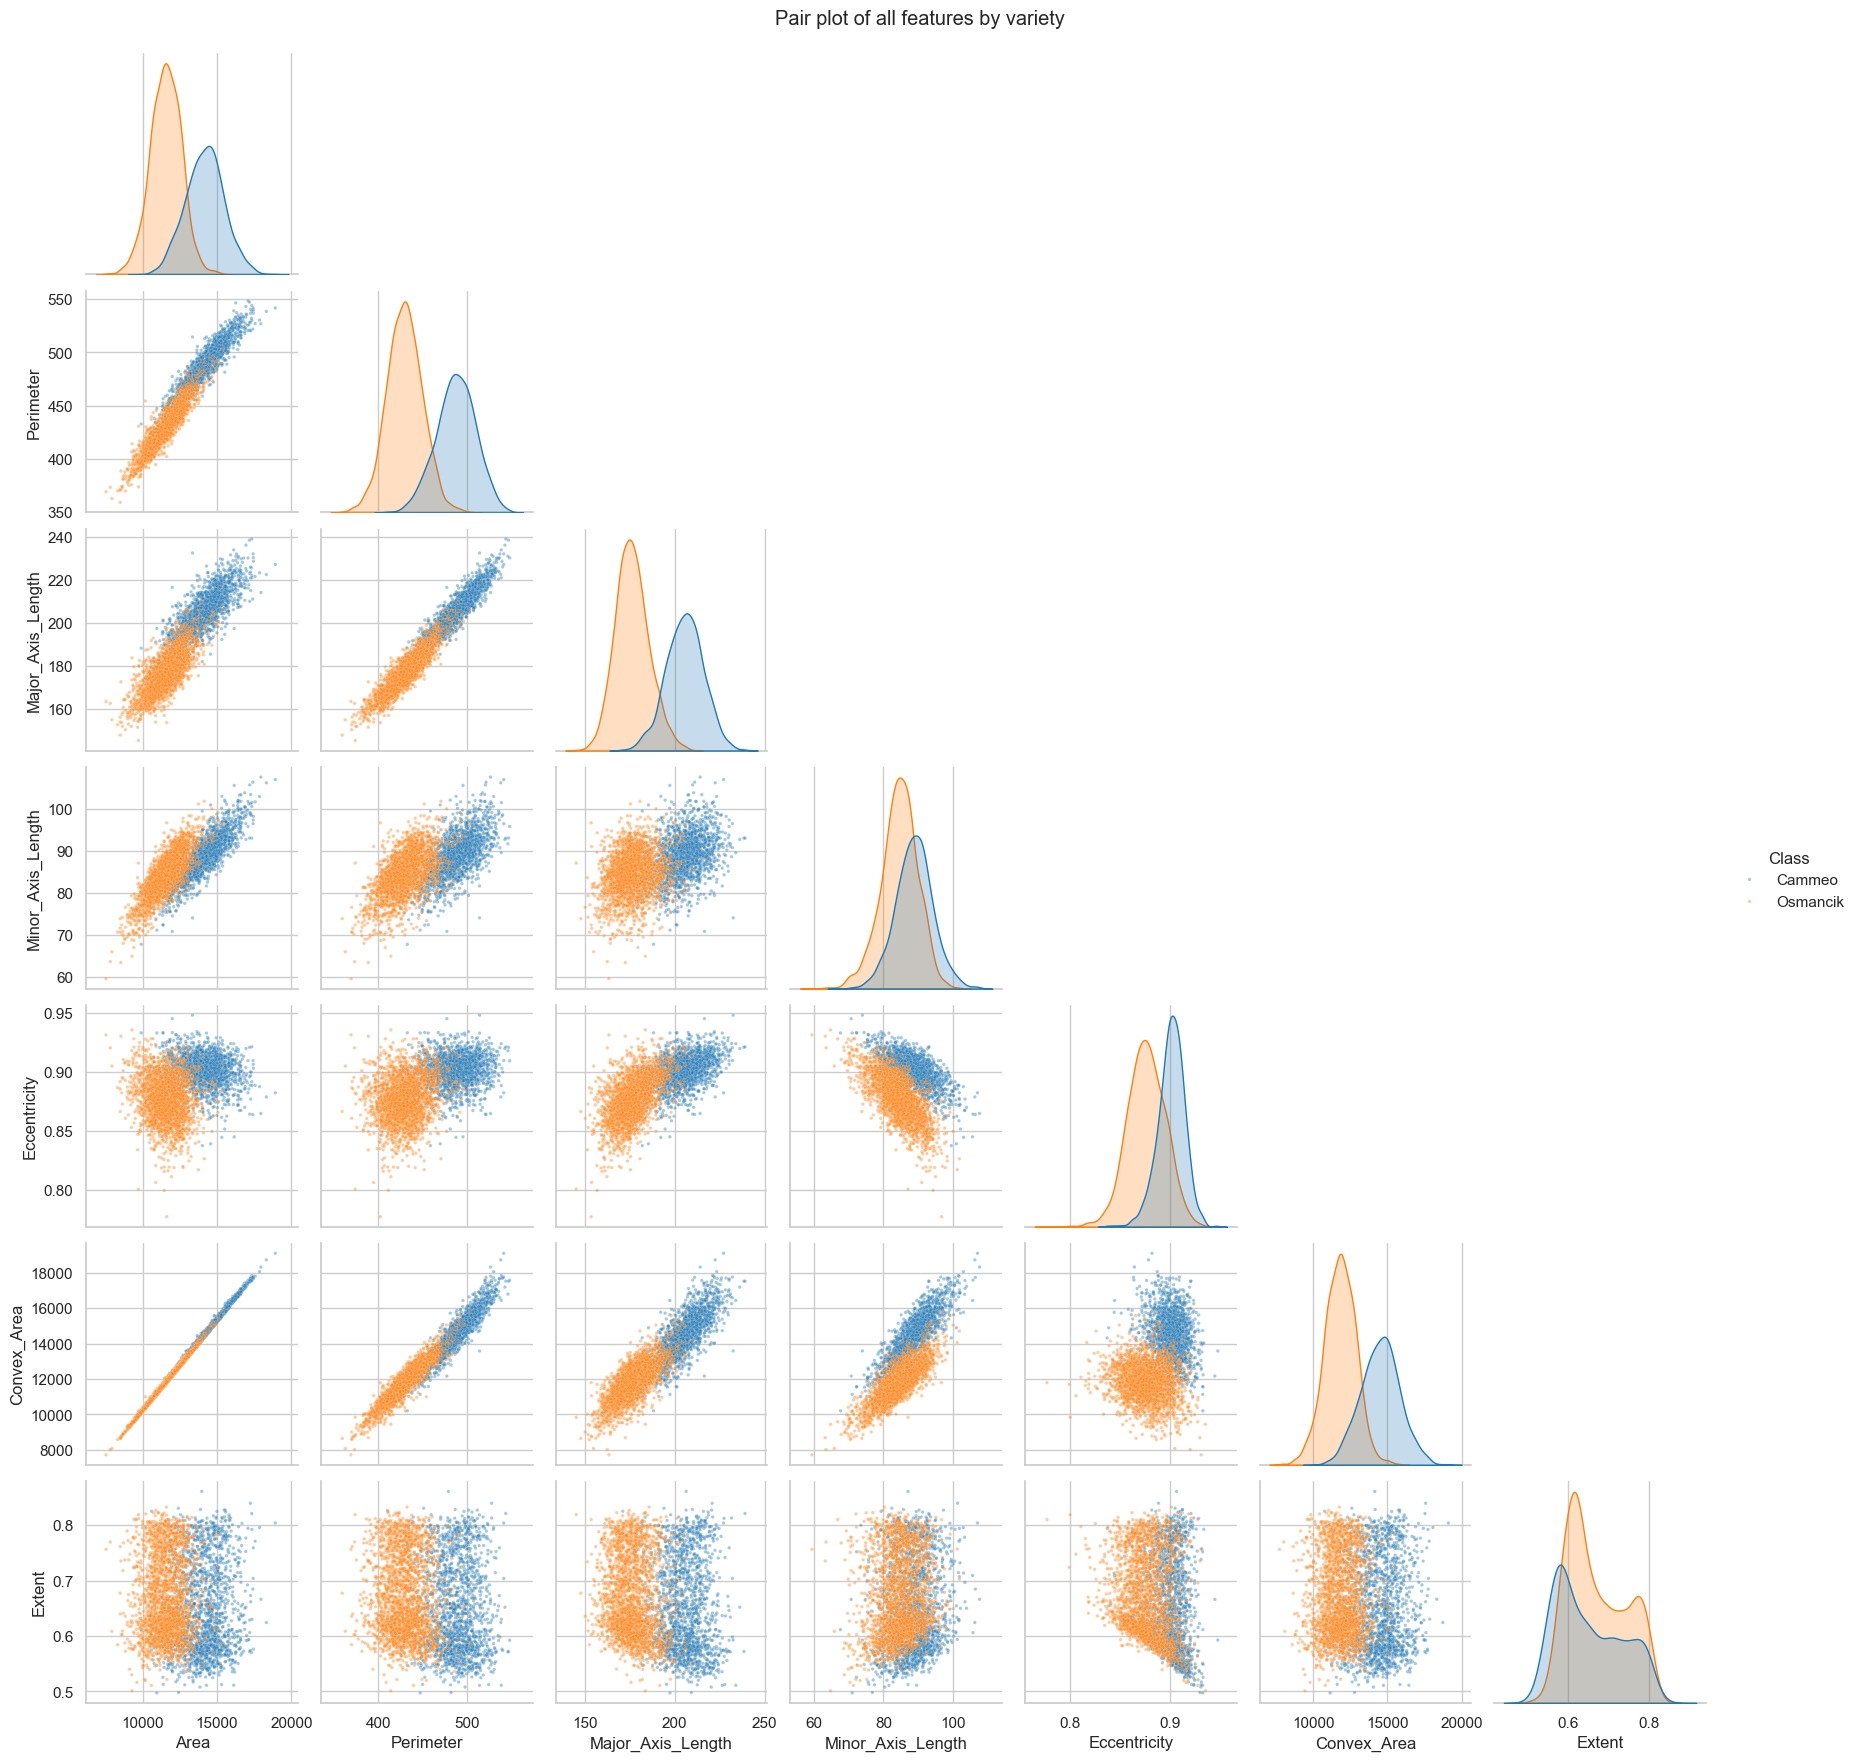

In [14]:
g = sns.pairplot(df, vars=FEATURES, hue=TARGET, palette=PALETTE, corner=True,
                 plot_kws={'s': 6, 'alpha': 0.4}, diag_kind='kde')
g.figure.suptitle('Pair plot of all features by variety', y=1.01)
savefig('08_pair_plot')
plt.show()

## 5. Identify Problems — Data Quality
### 5.1 Data quality dimensions (Lecture 2)
| Dimension | Meaning | Check used here |
|---|---|---|
| Completeness | No important values missing | Missing values per column |
| Uniqueness | No duplicate records | Exact and near duplicates |
| Consistency | Same data represented the same way | Label spelling; inconsistent labels (identical grains with different classes) |
| Validity | Data follows rules | Geometric rules every real grain must satisfy |
| Accuracy | Data reflects real values | Noise and outliers (section 5.2) |
| Timeliness | Data is up to date | Collection context (stated, not computed) |

In [15]:
def round_sig(s, sig=4):
    return s.apply(lambda v: float(f'{v:.{sig}g}'))

missing_total = int(df.isna().sum().sum())
exact_dups = int(df.duplicated().sum())
near_dups = int(df[FEATURES].apply(round_sig).duplicated().sum()) - int(df[FEATURES].duplicated().sum())
label_values = sorted(df[TARGET].unique())
label_groups = df.groupby(FEATURES)[TARGET].nunique()
inconsistent_labels = int((label_groups > 1).sum())

validity_rules = {
    'All measurements > 0':        int((df[FEATURES] <= 0).any(axis=1).sum()),
    'Convex_Area >= Area':         int((df['Convex_Area'] < df['Area']).sum()),
    'Major_Axis >= Minor_Axis':    int((df['Major_Axis_Length'] < df['Minor_Axis_Length']).sum()),
    'Eccentricity between 0 and 1': int((~df['Eccentricity'].between(0, 1)).sum()),
    'Extent between 0 and 1':      int((~df['Extent'].between(0, 1)).sum()),
}
validity_violations = sum(validity_rules.values())

def status(n): return 'OK' if n == 0 else 'Review'

quality_report = pd.DataFrame([
    ['Completeness', 'Missing values (all cells)', missing_total, status(missing_total),
     'Missing values reduce training data and accuracy (Lecture 2)'],
    ['Uniqueness', 'Exact duplicate rows', exact_dups, status(exact_dups),
     'Duplicates bias the model toward repeated cases'],
    ['Uniqueness', 'Near duplicates (equal to 4 significant figures)', near_dups, status(near_dups),
     'Near-identical grains could appear in both train and test sets'],
    ['Consistency', f'Label values found: {label_values}', len(label_values), status(len(label_values) - 2),
     'Misspelled labels would create false extra classes'],
    ['Consistency', 'Inconsistent labels (same measurements, different class)', inconsistent_labels, status(inconsistent_labels),
     'Conflicting labels confuse training and no model can fix them'],
    ['Validity', 'Rows breaking a geometric rule', validity_violations, status(validity_violations),
     'Impossible shapes would indicate measurement errors'],
    ['Accuracy', 'Outliers / noise', 'see 5.2', '-',
     'Outliers can distort statistics and bias training'],
    ['Timeliness', 'One collection from one imaging setup; no time variable', '-', 'Note',
     'Model is only valid while future grains are imaged the same way'],
], columns=['Dimension', 'Check', 'Result', 'Status', 'Effect on the task'])
quality_report.to_csv(os.path.join(OUTPUT_DIR, 'data_quality_report.csv'), index=False)
display(quality_report)

print('Validity rule details:')
for rule, n in validity_rules.items():
    print(f'  {rule:<30}: {n} violations')
print('\nMissing values per column:')
print(df.isna().sum())

,Dimension,Check,Result,Status,Effect on the task
0,Completeness,Missing values (all cells),0,OK,Missing values reduce training data and accura...
1,Uniqueness,Exact duplicate rows,0,OK,Duplicates bias the model toward repeated cases
2,Uniqueness,Near duplicates (equal to 4 significant figures),0,OK,Near-identical grains could appear in both tra...
3,Consistency,"Label values found: ['Cammeo', 'Osmancik']",2,OK,Misspelled labels would create false extra cla...
4,Consistency,"Inconsistent labels (same measurements, differ...",0,OK,Conflicting labels confuse training and no mod...
5,Validity,Rows breaking a geometric rule,0,OK,Impossible shapes would indicate measurement e...
6,Accuracy,Outliers / noise,see 5.2,-,Outliers can distort statistics and bias training
7,Timeliness,One collection from one imaging setup; no time...,-,Note,Model is only valid while future grains are im...


Validity rule details:
  All measurements > 0          : 0 violations
  Convex_Area >= Area           : 0 violations
  Major_Axis >= Minor_Axis      : 0 violations
  Eccentricity between 0 and 1  : 0 violations
  Extent between 0 and 1        : 0 violations

Missing values per column:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64


**Observations — Data quality**
- No missing values, no exact or near duplicates, no inconsistent labels, exactly two correctly spelled class labels, and no rows breaking a geometric rule.
- **Effect on the task:** no imputation, deduplication or label correction is needed. The main quality questions are outliers (5.2) and how representative the data is (6.2).

### 5.2 Outliers (IQR method) and noise
Outliers are counted two ways: across the whole dataset, and **within each variety**. The two varieties differ in size, so a normal large Cammeo grain can look like an outlier when both are pooled.
Outliers may be **errors** (e.g. broken grains, image-measurement noise) or **rare but valid** grains (Lecture 2). Nothing is removed here; the preprocessing teammate decides and records the decision.
The group-comparison boxplots in 4.4 show the within-variety view visually.

In [16]:
def iqr_flags(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

flags_within = pd.DataFrame(index=df.index)
rows = []
for f in FEATURES:
    overall = iqr_flags(df[f])
    flags_within[f] = df.groupby(TARGET)[f].transform(iqr_flags).astype(bool)
    rows.append({'Feature': f,
                 'Outliers (whole dataset)': int(overall.sum()),
                 'Outliers (within variety)': int(flags_within[f].sum()),
                 '% of rows (within variety)': round(flags_within[f].mean() * 100, 2)})
outlier_summary = pd.DataFrame(rows)
outlier_summary.to_csv(os.path.join(OUTPUT_DIR, 'outlier_summary.csv'), index=False)
display(outlier_summary)

n_flags = flags_within.sum(axis=1)
n_outlier_rows = int((n_flags > 0).sum())
any_outlier_pct = n_outlier_rows / len(df) * 100
print(f'Rows with at least one within-variety outlier: {n_outlier_rows} ({any_outlier_pct:.2f}%)')

,Feature,Outliers (whole dataset),Outliers (within variety),% of rows (within variety)
0,Area,4,36,0.9400
1,Perimeter,0,39,1.0200
2,Major_Axis_Length,0,40,1.0500
3,Minor_Axis_Length,65,68,1.7800
4,Eccentricity,21,52,1.3600
5,Convex_Area,3,37,0.9700
6,Extent,0,0,0.0000


Rows with at least one within-variety outlier: 154 (4.04%)


**Observations — Outliers**
- Pooled IQR finds few outliers (e.g. 4 for Area, 0 for Perimeter) because the two varieties' size ranges cover each other's extremes. Within each variety there are more (36 for Area, 68 for Minor Axis Length), at most about 1.8% of rows per feature. Extent has none.
- About 4% of rows have at least one within-variety outlier. None break a geometric rule (5.1), so they look like real but unusual grains rather than recording errors.
- **Effect on the task:** removing 4% of the data is not clearly justified. Keeping them and using robust scaling (less sensitive to outliers, Lecture 3), or testing both options, is a defensible choice for the preprocessing teammate.

### 5.3 Class imbalance
The **majority-class accuracy** is what a model scores by always predicting the most common variety. Every model must clearly beat it (Lecture 4: imbalance can make accuracy misleading).

,count,percent
Class,,
Osmancik,2180,57.2200
Cammeo,1630,42.7800


Imbalance ratio (majority / minority): 1.34
Majority-class accuracy (always predicting Osmancik): 0.5722


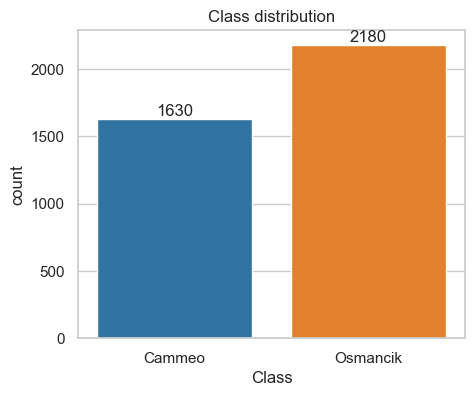

In [17]:
counts = df[TARGET].value_counts()
balance = pd.DataFrame({'count': counts, 'percent': (counts / counts.sum() * 100).round(2)})
display(balance)

imbalance_ratio = counts.max() / counts.min()
majority_acc = counts.max() / counts.sum()
print(f'Imbalance ratio (majority / minority): {imbalance_ratio:.2f}')
print(f'Majority-class accuracy (always predicting {counts.idxmax()}): {majority_acc:.4f}')

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x=TARGET, hue=TARGET, palette=PALETTE, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Class distribution')
savefig('09_class_distribution')
plt.show()

**Observations — Class imbalance**
- Osmancik 2,180 (57.2%) and Cammeo 1,630 (42.8%). This is only slightly uneven compared with Lecture 4's imbalanced example (80% / 20%).
- A model that always predicts Osmancik would already reach 57.2% accuracy, so accuracy alone is not enough evidence (Lecture 4).
- **Effect on the task:** a **stratified** train–test split keeps the same proportions in both sets. Class weighting is a simple option if needed; SMOTE is likely unnecessary and, per Lecture 4, is less effective when classes overlap, as they do here (4.4).

### 5.4 Data leakage (Lecture 2)
- **Target leakage:** every feature is measured from the grain image, which exists before the variety is known, so no feature contains information about the target that would be unavailable at prediction time. The strongest correlation with the target (r ≈ 0.83, section 4.6) is high but not a perfect separator, which fits a genuine physical difference rather than leakage.
- **Train–test contamination:** this EDA fits nothing. Scaling, transformation, PCA and feature selection must be fitted on the training set only, ideally inside a `Pipeline`, after a stratified split (Lectures 2–4). For example, normalizing the whole dataset before splitting would be contamination (Lecture 2).

## 6. Ready for ML
### 6.1 Hand-off: EDA evidence → preprocessing implication
Each row links an EDA finding to a preprocessing option from Lectures 3–4. The preprocessing teammate makes the final decision and records it.

In [18]:
skewed = stat_summary.index[stat_summary['skewness'].abs() > 1].tolist()
range_ratio = stat_summary['range'].max() / stat_summary['range'].min()
max_outlier_pct = outlier_summary['% of rows (within variety)'].max()

handoff = pd.DataFrame([
    ['Missing values', f'{missing_total} missing cells',
     'No imputation needed' if missing_total == 0 else 'Choose imputation: median (skewed) or mean (normal), fitted on train only'],
    ['Duplicates', f'{exact_dups} exact, {near_dups} near',
     'Nothing to remove' if exact_dups + near_dups == 0 else 'Review duplicates; remove exact duplicates before splitting'],
    ['Variable types', '7 numerical features, binary target',
     'No one-hot/ordinal encoding needed; label-encode the target only (Cammeo=1, Osmancik=0)'],
    ['Feature scales', f'Largest range is {range_ratio:,.0f}x the smallest',
     'Scale for Logistic Regression, SVM, KNN (standardization or robust scaling); not needed for Decision Tree / Random Forest'],
    ['Outliers', f'Up to {max_outlier_pct:.2f}% of rows per feature within variety; {any_outlier_pct:.1f}% of rows have at least one',
     'Keep if valid rare grains; robust scaling is less outlier-sensitive than standardization; test the effect of removal'],
    ['Skewness', f'|skew| > 1: {skewed if skewed else "none"}',
     'Consider log / square-root / Box-Cox (all values are positive)' if skewed else 'No transformation needed'],
    ['Redundant features', f'{len(redundant_pairs)} pairs with |r| >= 0.9',
     'Candidates for feature selection (drop redundant) or PCA; affects coefficient-based importance'],
    ['Class imbalance', f'{balance["percent"].max():.1f}% / {balance["percent"].min():.1f}% (ratio {imbalance_ratio:.2f})',
     'Stratified train-test split; class weighting if needed; SMOTE likely unnecessary and less effective with overlapping classes'],
    ['Train-test split', 'Lecture 2: 80/20; Lecture 1: 70/15/15',
     'Stratified split before any preprocessing; fit all preprocessing on the training set only (Pipeline)'],
    ['Feature relevance', f'Strongest: {corr_target.index[0]}; weakest: {corr_target.index[-1]}',
     'Feature selection candidates; compare with tree-based importance in Section 10.4'],
], columns=['Issue', 'EDA evidence', 'Implication for preprocessing'])
handoff.to_csv(os.path.join(OUTPUT_DIR, 'preprocessing_handoff.csv'), index=False)
pd.set_option('display.max_colwidth', None)
display(handoff)

,Issue,EDA evidence,Implication for preprocessing
0,Missing values,0 missing cells,No imputation needed
1,Duplicates,"0 exact, 0 near",Nothing to remove
2,Variable types,"7 numerical features, binary target","No one-hot/ordinal encoding needed; label-encode the target only (Cammeo=1, Osmancik=0)"
3,Feature scales,"Largest range is 66,614x the smallest","Scale for Logistic Regression, SVM, KNN (standardization or robust scaling); not needed for Decision Tree / Random Forest"
4,Outliers,Up to 1.78% of rows per feature within variety; 4.0% of rows have at least one,Keep if valid rare grains; robust scaling is less outlier-sensitive than standardization; test the effect of removal
5,Skewness,|skew| > 1: none,No transformation needed
6,Redundant features,6 pairs with |r| >= 0.9,Candidates for feature selection (drop redundant) or PCA; affects coefficient-based importance
7,Class imbalance,57.2% / 42.8% (ratio 1.34),Stratified train-test split; class weighting if needed; SMOTE likely unnecessary and less effective with overlapping classes
8,Train-test split,Lecture 2: 80/20; Lecture 1: 70/15/15,Stratified split before any preprocessing; fit all preprocessing on the training set only (Pipeline)
9,Feature relevance,Strongest: Major_Axis_Length; weakest: Extent,Feature selection candidates; compare with tree-based importance in Section 10.4


### 6.2 Modelling assumptions check (Lecture 2)
| Assumption | Assessment |
|---|---|
| Representative data | One collection of two varieties imaged with one camera setup. Representative of that setting only, not of other varieties or growing conditions. |
| Good quality data | See the data quality report (section 5.1). |
| Relevant features | All seven are physical grain measurements; correlation with the target (section 4.6) shows which are most relevant. |
| Similar future data | Holds only if future grains are imaged with the same setup. A different camera or resolution changes pixel-based sizes — a deployment limitation. |

**Limitations to pass to the recommendation:** only two varieties (the model cannot recognise any other variety or mixed samples); pixel units tie the model to one imaging setup; broken or unusual grains may be misclassified; the varieties overlap on width and Extent, so some error is unavoidable.

## 7. EDA insight log
Generated from the results above. Copy it into the group's EDA Insight Log and add your own interpretation in the report.

In [19]:

top_feat = corr_target.index[0]
weak_feat = corr_target.index[-1]

insights = pd.DataFrame([
    ['E1', f'{df.shape[0]} samples, {len(FEATURES)} numerical features, binary target.',
     'Sections 3.1-3.2', 'Small, structured, labelled dataset suited to supervised classification.', 'Modelling'],

    ['E2', f'{missing_total} missing cells; {exact_dups} exact and {near_dups} near duplicates; {inconsistent_labels} inconsistent labels; {validity_violations} validity violations.',
     'Section 5.1', 'Shows how much data cleaning is needed.', 'Preprocessing'],

    ['E3', f'Classes {balance["percent"].to_dict()}; imbalance ratio {imbalance_ratio:.2f}; majority-class accuracy {majority_acc:.4f}.',
     'Section 5.3', 'Use a stratified split; models must beat the majority-class accuracy; report more than accuracy.', 'Preprocessing / Evaluation'],

    ['E4', f'Strongest feature-target correlation: {top_feat} (r = {corr_target.iloc[0, 0]:.3f}); weakest: {weak_feat} (r = {corr_target.iloc[-1, 0]:.3f}).',
     'Section 4.6', 'First ranking to support feature selection; compare with tree-based importance.', 'Feature selection'],

    ['E5', f'{len(redundant_pairs)} redundant feature pairs (|r| >= 0.9).',
     'Section 4.7', 'Consider feature selection or PCA; correlated features can share importance.', 'Preprocessing / Feature selection'],

    ['E6', f'Up to {max_outlier_pct:.2f}% outliers per feature within variety; {any_outlier_pct:.1f}% of rows have at least one; no geometric rule broken.',
     'Section 5.2', 'Decide keep / remove; consider robust scaling.', 'Preprocessing'],

    ['E7', f'Feature ranges differ by a factor of about {range_ratio:,.0f}.',
     'Section 4.1', 'Scaling needed for distance- and gradient-based models.', 'Preprocessing'],

    ['E8', 'Size features are in pixels from one imaging setup.',
     'Sections 3.2, 6.2', 'Model may not transfer to a new camera without recalibration (limitation).', 'Recommendation'],

    ['E9', 'Size features separate the varieties clearly; Minor Axis Length and Extent overlap heavily.',
     'Section 4.4', 'Some misclassification is unavoidable; grain length is the key discriminating measurement.', 'Modelling / Feature selection'],

], columns=[
    'ID',
    'Observation',
    'Evidence',
    'Implication',
    'Hand-off to'
])

insights.to_csv(
    os.path.join(OUTPUT_DIR, 'eda_insight_log.csv'),
    index=False
)

insights

,ID,Observation,Evidence,Implication,Hand-off to
0,E1,"3810 samples, 7 numerical features, binary target.",Sections 3.1-3.2,"Small, structured, labelled dataset suited to supervised classification.",Modelling
1,E2,0 missing cells; 0 exact and 0 near duplicates; 0 inconsistent labels; 0 validity violations.,Section 5.1,Shows how much data cleaning is needed.,Preprocessing
2,E3,"Classes {'Osmancik': 57.22, 'Cammeo': 42.78}; imbalance ratio 1.34; majority-class accuracy 0.5722.",Section 5.3,Use a stratified split; models must beat the majority-class accuracy; report more than accuracy.,Preprocessing / Evaluation
3,E4,Strongest feature-target correlation: Major_Axis_Length (r = 0.828); weakest: Extent (r = -0.118).,Section 4.6,First ranking to support feature selection; compare with tree-based importance.,Feature selection
4,E5,6 redundant feature pairs (|r| >= 0.9).,Section 4.7,Consider feature selection or PCA; correlated features can share importance.,Preprocessing / Feature selection
5,E6,Up to 1.78% outliers per feature within variety; 4.0% of rows have at least one; no geometric rule broken.,Section 5.2,Decide keep / remove; consider robust scaling.,Preprocessing
6,E7,"Feature ranges differ by a factor of about 66,614.",Section 4.1,Scaling needed for distance- and gradient-based models.,Preprocessing
7,E8,Size features are in pixels from one imaging setup.,"Sections 3.2, 6.2",Model may not transfer to a new camera without recalibration (limitation).,Recommendation
8,E9,Size features separate the varieties clearly; Minor Axis Length and Extent overlap heavily.,Section 4.4,Some misclassification is unavoidable; grain length is the key discriminating measurement.,Modelling / Feature selection


## 8. Export files for the group

In [20]:
df.to_csv(os.path.join(OUTPUT_DIR, 'rice_canonical.csv'), index=False)
pd.Series(fingerprint).astype(str).to_csv(os.path.join(OUTPUT_DIR, 'dataset_fingerprint.csv'), header=['value'])

for root, _, files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        print(os.path.relpath(os.path.join(root, f), OUTPUT_DIR))

correlation_with_target.csv
data_dictionary.csv
data_quality_report.csv
dataset_fingerprint.csv
eda_insight_log.csv
outlier_summary.csv
preprocessing_handoff.csv
rice_canonical.csv
statistical_summary.csv
figures\01_histograms.png
figures\02_boxplots.png
figures\03_group_comparison_boxplots.png
figures\04_group_comparison_histograms.png
figures\05_scatter_plots.png
figures\06_correlation_with_target.png
figures\07_correlation_heatmap.png
figures\08_pair_plot.png
figures\09_class_distribution.png



### 8.1 EDA decision log

| # | Decision | Options considered | Choice | Reason / evidence |
|---|---|---|---|---|
| D-EDA-1 | How to obtain the data | Manual download to Drive / `ucimlrepo` every run / `ucimlrepo` once + Drive snapshot | `ucimlrepo` once + snapshot | Official verifiable source; identical data for all members; fingerprint in 2.4 |
| D-EDA-2 | Data used for EDA | Full dataset / training set only | Full dataset, descriptive only | EDA fits nothing; all preprocessing is fitted on the training set after the split |
| D-EDA-3 | Outlier detection method | IQR on whole dataset / IQR within each variety | Both reported; within-variety used for decisions | Varieties differ in size: Area has 4 outliers pooled but 36 within varieties |
| D-EDA-4 | Outlier handling at EDA stage | Remove / cap / keep and report | Keep and report | Removal is a preprocessing decision; outliers break no geometric rule |
| D-EDA-5 | Target encoding for correlation | Cammeo = 1 / Osmancik = 1 | Cammeo = 1 | Binary target → label encoding (Lecture 3); a convention only. Member 2's pipeline uses LabelEncoder (Cammeo = 0) |
| D-EDA-6 | Feature relevance at EDA stage | Correlation with target (filter) / model-based importance | Correlation with target | Model-free and fits nothing (Lecture 4); model-based importance is done in 10.4 |
| D-EDA-7 | Recommended split | Random / stratified | Stratified | Classes are 57:43; stratified sampling preserves proportions (Lectures 2, 4) |
| D-EDA-8 | Secondary lens | Feature-importance secondary lens / primary lens only | Primary lens only | The descriptor makes a secondary lens optional and rewards coherence over extra analysis; feature importance is still used for feature selection (10.4) |


# Member 2: Data Preprocessing and Feature Engineering


# 9. Data Preprocessing

Data preprocessing is the foundational stage where raw dataset observations are cleaned, structured, and transformed into a reliable format suitable for machine learning algorithms.

### Import Data Preprocessing libraries

In [21]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler




### 9.1 Verification of Data Integrity: Missing Values & Duplicates
Before performing any data transformations, the dataset must be audited for data quality issues:
1. **Missing Value Audit:** Real-world datasets often suffer from unrecorded measurements, which degrade learning performance or crash estimators. If values are missing, appropriate imputation (mean, median, or mode) must be applied.
2. **Duplicate Record Audit:** Identical rows introduce artificial frequency bias, skew model weights towards over-represented instances, and lead to overly optimistic validation performance.

In this step, we verify null counts and detect duplicate rows across all grain measurements.

In [22]:
# ---9.1: Missing Values and Duplicate Audit ---
print("=" * 60)
print("1. MISSING VALUE AUDIT")
print("=" * 60)
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage (%)': missing_pct})
display(missing_df)

print("\n" + "=" * 60)
print("2. DUPLICATE RECORD AUDIT")
print("=" * 60)
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows detected: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicate rows removed. New dataset shape: {df.shape}")
else:
    print("Dataset integrity verified: zero missing entries and zero duplicate rows.")

1. MISSING VALUE AUDIT


,Missing Count,Percentage (%)
Area,0,0.0000
Perimeter,0,0.0000
Major_Axis_Length,0,0.0000
Minor_Axis_Length,0,0.0000
Eccentricity,0,0.0000
Convex_Area,0,0.0000
Extent,0,0.0000
Class,0,0.0000



2. DUPLICATE RECORD AUDIT
Total duplicate rows detected: 0
Dataset integrity verified: zero missing entries and zero duplicate rows.


### 9.2 Outlier Inspection and Treatment Strategy
Outliers are extreme observations situated far from the core empirical distribution.
* **IQR Rule:** A data point is statistically flagged as an outlier if it falls below $Q_1 - 1.5 \times \text{IQR}$ or above $Q_3 + 1.5 \times \text{IQR}$, where $\text{IQR} = Q_3 - Q_1$.
* **Domain Consideration:** In morphological imaging of biological specimens such as rice grains, natural biological variation produces exceptionally large or small grains.
* **Treatment Decision:** Because the grains were imaged under controlled laboratory conditions, these observations represent genuine biological diversity rather than measurement or sensor errors. Removing or heavily truncating them would strip the classifier of real-world variance. Therefore, we quantify the outliers per feature to confirm data bounds without discarding valid samples.

In [23]:
# ---9.2: Outlier Quantification (IQR Method) ---
print("=" * 60)
print("OUTLIER AUDIT VIA INTERQUARTILE RANGE (IQR)")
print("=" * 60)

outlier_summary = []
for col in FEATURES:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    count = len(outliers)
    pct = (count / len(df)) * 100

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': count,
        'Percentage (%)': pct
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)
print("Finding: Outlier proportions are low to moderate and reflect natural biological variability.")
print("Decision: Retain all natural grain samples to preserve real-world boundary representations.")

OUTLIER AUDIT VIA INTERQUARTILE RANGE (IQR)


,Feature,Lower Bound,Upper Bound,Outlier Count,Percentage (%)
0,Area,"7,501.2500","17,819.2500",4,0.1050
1,Perimeter,339.8363,569.9922,0,0.0000
2,Major_Axis_Length,130.5590,247.3453,0,0.0000
3,Minor_Axis_Length,71.6137,101.2616,65,1.7060
4,Eccentricity,0.8271,0.9479,21,0.5512
5,Convex_Area,"7,639.6250","18,270.6250",3,0.0787
6,Extent,0.4073,0.9181,0,0.0000


Finding: Outlier proportions are low to moderate and reflect natural biological variability.
Decision: Retain all natural grain samples to preserve real-world boundary representations.


### 9.3 Target Variable Encoding
Machine learning classification algorithms require mathematical inputs and numerical target vectors rather than raw text strings.
* The target attribute `Class` contains two distinct rice varieties: **Cammeo** and **Osmancik**.
* **Label Encoding** maps binary nominal categories directly to $\{0, 1\}$.
* We map:
  * **Cammeo $\rightarrow$ 0**
  * **Osmancik $\rightarrow$ 1**

This creates a clean, standard binary ground-truth vector ($y$) for downstream loss functions.

In [24]:
# --- 9.3: Target Variable Encoding ---

label_encoder = LabelEncoder()
df['Class_Encoded'] = label_encoder.fit_transform(df[TARGET])

target_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("=" * 60)
print("TARGET VARIABLE ENCODING MAPPING")
print("=" * 60)
for k, v in target_mapping.items():
    print(f"  Class '{k}' -> {v}")

print("\nEncoded Target Distribution:")
print(df['Class_Encoded'].value_counts().rename(index={0: 'Cammeo (0)', 1: 'Osmancik (1)'}))

TARGET VARIABLE ENCODING MAPPING
  Class 'Cammeo' -> 0
  Class 'Osmancik' -> 1

Encoded Target Distribution:
Class_Encoded
Osmancik (1)    2180
Cammeo (0)      1630
Name: count, dtype: int64


### 9.4 Leakage-Free Stratified Train-Test Separation
A critical requirement in rigorous machine learning is the **prevention of data leakage**. Data leakage occurs when information from the evaluation/test set inadvertently leaks into the training pipeline.
* **Train-Only Fitting Rule:** All subsequent preprocessing calculations (such as mean, standard deviation, min, max, or feature selection statistics) must be computed **strictly on the training partition**. The test set must be treated as completely unseen real-world data.
* **Stratified Splitting:** In binary classification, simple random sampling risks shifting class proportions between splits. **Stratified splitting** preserves the exact relative class proportions (Cammeo vs. Osmancik) across both subsets.
* We partition the data into **80% training** and **20% testing** sets.

In [25]:
# ---9.4: Leakage-Free Stratified Train/Test Split ---

X_raw = df[FEATURES].copy()
y = df['Class_Encoded'].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("STRATIFIED TRAIN/TEST SPLIT VERIFICATION")
print("=" * 60)
print(f"Total Dataset Instances : {len(df)}")
print(f"Training Partition Size : {X_train_raw.shape[0]} samples ({X_train_raw.shape[0]/len(df)*100:.1f}%)")
print(f"Testing Partition Size  : {X_test_raw.shape[0]} samples ({X_test_raw.shape[0]/len(df)*100:.1f}%)")

train_dist = y_train.value_counts(normalize=True) * 100
test_dist = y_test.value_counts(normalize=True) * 100
split_comparison = pd.DataFrame({
    'Train Ratio (%)': train_dist,
    'Test Ratio (%)': test_dist
}, index=[0, 1]).rename(index={0: 'Cammeo (0)', 1: 'Osmancik (1)'})

print("\nClass Proportion Alignment:")
display(split_comparison)

STRATIFIED TRAIN/TEST SPLIT VERIFICATION
Total Dataset Instances : 3810
Training Partition Size : 3048 samples (80.0%)
Testing Partition Size  : 762 samples (20.0%)

Class Proportion Alignment:


,Train Ratio (%),Test Ratio (%)
Cammeo (0),42.7822,42.7822
Osmancik (1),57.2178,57.2178



### 9.5 Class Imbalance Assessment and Resampling Evaluation

Class imbalance occurs when one class substantially outnumbers another, which can bias estimators toward the majority class.

- In our training split:
  - **Osmancik:** approximately 57.2%
  - **Cammeo:** approximately 42.8%

- **Evaluation & Decision:** Lecture 4 shows an imbalanced dataset as 80:20. At about 57:43 our classes are only mildly uneven, so oversampling or undersampling is not needed.

- Generating synthetic data points with SMOTE here risks introducing artificial noise because the two varieties overlap on several features (EDA 4.4), and SMOTE is less effective with overlapping classes. Therefore, the original natural class balance is preserved and a stratified split is used instead.


In [26]:

# --- 9.5: Class Imbalance Ratio Check ---

print("=" * 60)
print("CLASS IMBALANCE EVALUATION")
print("=" * 60)

cammeo_count = (y_train == 0).sum()
osmancik_count = (y_train == 1).sum()
imbalance_ratio = osmancik_count / cammeo_count

print(f"Training Class 0 (Cammeo)  : {cammeo_count} ({cammeo_count/len(y_train)*100:.2f}%)")
print(f"Training Class 1 (Osmancik): {osmancik_count} ({osmancik_count/len(y_train)*100:.2f}%)")
print(f"Imbalance Ratio (Majority / Minority): {imbalance_ratio:.2f} : 1.00")

print(f"\nDecision: the split is approximately {osmancik_count/len(y_train)*100:.0f}:{cammeo_count/len(y_train)*100:.0f}, "
      "only mildly uneven compared with the 80:20 example in Lecture 4. "
      "Resampling/SMOTE is not applied; stratified splitting keeps the proportions.")

CLASS IMBALANCE EVALUATION
Training Class 0 (Cammeo)  : 1304 (42.78%)
Training Class 1 (Osmancik): 1744 (57.22%)
Imbalance Ratio (Majority / Minority): 1.34 : 1.00

Decision: the split is approximately 57:43, only mildly uneven compared with the 80:20 example in Lecture 4. Resampling/SMOTE is not applied; stratified splitting keeps the proportions.


### 9.6 Numerical Feature Scaling Comparison
The EDA statistical summary showed vast differences in feature scales (for example, `Area` variance exceeds $3 \times 10^6$, whereas `Eccentricity` variance is $\approx 0.0004$). Without scaling, distance-based models (KNN, SVM) and gradient-based algorithms (Logistic Regression) will be dominated by large-magnitude features.

We evaluate three standard scaling techniques:
1. **StandardScaler (Z-Score):** Centers each feature around $\mu = 0$ with $\sigma = 1$:
   $$z = \frac{x - \mu}{\sigma}$$
2. **MinMaxScaler:** Normalizes values strictly between:
   $$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$
3. **RobustScaler:** Uses median and interquartile range ($Q_3 - Q_1$), minimizing the influence of peripheral values:
   $$x' = \frac{x - \text{median}}{\text{IQR}}$$

To prevent data leakage, all scalers are **fitted strictly on `X_train_raw`** and then applied to transform both the training and testing sets.

In [27]:
# ---9.6: Comparative Feature Scaling (Fitted on Train Only) ---

std_scaler = StandardScaler().fit(X_train_raw)
minmax_scaler = MinMaxScaler().fit(X_train_raw)
robust_scaler = RobustScaler().fit(X_train_raw)

# Inspect scaling behavior on a representative large-scale feature ('Area') and a ratio feature ('Eccentricity')
sample_cols = ['Area', 'Eccentricity']

scaling_comparison = pd.DataFrame({
    'Raw (Mean ± Std)': [f"{X_train_raw[c].mean():.2f} ± {X_train_raw[c].std():.2f}" for c in sample_cols],
    'StandardScaler [0, 1]': [f"{std_scaler.transform(X_train_raw)[:, X_train_raw.columns.get_loc(c)].mean():.2f} ± {std_scaler.transform(X_train_raw)[:, X_train_raw.columns.get_loc(c)].std():.2f}" for c in sample_cols],
    'MinMaxScaler [Min, Max]': [f"[{minmax_scaler.transform(X_train_raw)[:, X_train_raw.columns.get_loc(c)].min():.2f}, {minmax_scaler.transform(X_train_raw)[:, X_train_raw.columns.get_loc(c)].max():.2f}]" for c in sample_cols],
    'RobustScaler [Median, IQR]': [f"{np.median(robust_scaler.transform(X_train_raw)[:, X_train_raw.columns.get_loc(c)]):.2f}" for c in sample_cols]
}, index=sample_cols)

print("=" * 60)
print("SCALING METHOD COMPARISON (Fitted on X_train only)")
print("=" * 60)
display(scaling_comparison)
print("Recommendation: StandardScaler is ideal for normal-like geometric distributions, while RobustScaler safeguards against boundary points.")

SCALING METHOD COMPARISON (Fitted on X_train only)


,Raw (Mean ± Std),"StandardScaler [0, 1]","MinMaxScaler [Min, Max]","RobustScaler [Median, IQR]"
Area,12678.70 ± 1729.27,0.00 ± 1.00,"[0.00, 1.00]",0.00
Eccentricity,0.89 ± 0.02,-0.00 ± 1.00,"[0.00, 1.00]",0.00


Recommendation: StandardScaler is ideal for normal-like geometric distributions, while RobustScaler safeguards against boundary points.


# 10. Feature Engineering (FE)

Feature Engineering is the process of constructing new informative variables, transforming existing relationships, and selecting the most discriminative feature subset to boost model performance and interpretability.


### Import Feature Engineering libraries

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer



### 10.1 Domain-Specific Feature Construction
Raw pixel measurements describe independent 1D and 2D properties. By mathematically combining them, we can capture high-level geometric and morphological descriptors:
1. **Aspect Ratio ($AR$):** Ratio of grain length to width:
   $$AR = \frac{\text{Major\_Axis\_Length}}{\text{Minor\_Axis\_Length}}$$
   Long, slender grains (Cammeo) exhibit higher aspect ratios than rounder grains (Osmancik).
2. **Solidity / Convexity Density:** Ratio of boundary area to its convex envelope:
   $$\text{Solidity} = \frac{\text{Area}}{\text{Convex\_Area}}$$
   Measures boundary smoothness and compactness.
3. **Compactness / Roundness ($C$):** Isoperimetric quotient quantifying circularity:
   $$C = \frac{4 \cdot \pi \cdot \text{Area}}{\text{Perimeter}^2}$$
4. **Estimated Area Deviation:** Discrepancy between the observed pixel area and the theoretical area of an ellipse ($\frac{\pi}{4} \cdot L \cdot W$):
   $$\text{Area\_Diff} = \text{Area} - \left(\frac{\pi}{4} \cdot \text{Major\_Axis\_Length} \cdot \text{Minor\_Axis\_Length}\right)$$

In [29]:
# --- 10.1: Domain-Specific Feature Construction Function ---
def construct_domain_features(df_input):
    df_feat = df_input.copy()

    # 1. Aspect Ratio (Grain Slenderness)
    df_feat['Aspect_Ratio'] = df_feat['Major_Axis_Length'] / df_feat['Minor_Axis_Length']

    # 2. Solidity (Grain Convex Density)
    df_feat['Solidity'] = df_feat['Area'] / df_feat['Convex_Area']

    # 3. Compactness (Circularity Quotient)
    df_feat['Compactness'] = (4 * np.pi * df_feat['Area']) / (df_feat['Perimeter'] ** 2)

    # 4. Elliptical Area Deviation
    theoretical_ellipse_area = (np.pi / 4.0) * df_feat['Major_Axis_Length'] * df_feat['Minor_Axis_Length']
    df_feat['Elliptical_Area_Dev'] = df_feat['Area'] - theoretical_ellipse_area

    return df_feat

# Apply domain construction to training and testing sets independently
X_train_eng = construct_domain_features(X_train_raw)
X_test_eng = construct_domain_features(X_test_raw)

print("=" * 60)
print("ENGINEERED MORPHOLOGICAL FEATURES PREVIEW (Train Set)")
print("=" * 60)
display(X_train_eng[['Aspect_Ratio', 'Solidity', 'Compactness', 'Elliptical_Area_Dev']].head())
print(f"New feature count: {X_train_eng.shape[1]} features (from original {X_train_raw.shape[1]})")

ENGINEERED MORPHOLOGICAL FEATURES PREVIEW (Train Set)


,Aspect_Ratio,Solidity,Compactness,Elliptical_Area_Dev
1663,2.0065,0.9771,0.8009,-170.9083
263,2.2708,0.9766,0.7622,-146.9487
1823,1.9962,0.9739,0.8032,-180.4255
1665,2.3111,0.9798,0.7552,-106.4057
287,2.3439,0.9733,0.7375,-216.9082


New feature count: 11 features (from original 7)


### 10.2 Feature Interaction and Polynomial Expansions
Certain learning algorithms (e.g., linear classifiers) assume linear additive relationships. To allow models to capture non-linear interactions without manual tuning, we create:
* **Interaction Features:** The cross-product of key axial metrics:
  $$\text{Axis\_Interaction} = \text{Major\_Axis\_Length} \times \text{Minor\_Axis\_Length}$$
* **Quadratic Power Features:** Higher-order polynomial terms to capture non-linear curvature:
  $$\text{Perimeter\_Squared} = \text{Perimeter}^2$$

In [30]:
# --- 10.2: Interaction & Polynomial Features ---
for dataset in [X_train_eng, X_test_eng]:
    # Non-linear interaction between major and minor axes
    dataset['Axis_Interaction'] = dataset['Major_Axis_Length'] * dataset['Minor_Axis_Length']
    # Quadratic term capturing boundary scaling
    dataset['Perimeter_Sq'] = dataset['Perimeter'] ** 2

print("=" * 60)
print("INTERACTION AND POLYNOMIAL TERMS CREATED")
print("=" * 60)
display(X_train_eng[['Axis_Interaction', 'Perimeter_Sq']].head())
print(f"Total features after expansion: {X_train_eng.shape[1]}")

INTERACTION AND POLYNOMIAL TERMS CREATED


,Axis_Interaction,Perimeter_Sq
1663,"16,869.0339","205,200.8436"
263,"19,770.7983","253,591.8193"
1823,"14,591.8669","176,484.8613"
1665,"15,933.8363","206,471.1729"
287,"18,268.3242","240,787.4604"


Total features after expansion: 13


### 10.3 Multicollinearity and Redundancy Audit (Correlation Filter)
Constructing domain and interaction features often introduces **multicollinearity** (high correlation between pairs of features).
* Highly collinear variables provide duplicate information, inflate estimator variance, and obscure true feature importance.
* **Filter Rule:** We compute the Pearson correlation matrix **strictly on the training data**. When two features exhibit an absolute correlation $|r| > 0.95$, one is identified as redundant.
* We inspect collinear pairs and flag redundant features for removal.


**Feature selection decision from the redundancy audit**

- **Threshold:** the EDA  listed all pairs with |r| ≥ 0.9 as *candidates*. Here a stricter |r| > 0.95 is used to decide what to actually remove, so that only features that almost completely duplicate another are dropped.
- **Dropped:** `Convex_Area` (r = 0.999 with `Area`), `Perimeter` (r ≈ 0.97 with `Area`, `Major_Axis_Length` and `Convex_Area`), and `Axis_Interaction` (r = 0.999 with `Area`). `Perimeter_Sq` is not used in the final pipeline because it is a transform of the dropped `Perimeter`.
- **Kept despite being flagged:**
  - `Major_Axis_Length` is the strongest single feature (EDA r ≈ 0.83 with the target; top Random Forest importance in 10.4), so removing it would lose the most useful information.
  - `Aspect_Ratio` and `Eccentricity` are highly correlated (r ≈ 0.98) but both are kept because they describe grain shape in different ways. Logistic Regression's default L2 regularisation reduces the effect of this correlation on predictions. This is noted as a limitation for coefficient interpretation.


In [31]:
# ---10.3: Multicollinearity Audit via Correlation Matrix ---
corr_matrix = X_train_eng.corr().abs()

# Extract upper triangle of correlation matrix
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find pairs with correlation > 0.95
high_corr_pairs = [
    (column, row, upper_tri.loc[row, column])
    for column in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, column] > 0.95
]

print("=" * 60)
print("HIGHLY CORRELATED / REDUNDANT FEATURE PAIRS (|r| > 0.95)")
print("=" * 60)
high_corr_df = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Absolute Correlation'])
display(high_corr_df)

# List candidate features to drop based on severe redundancy
cols_to_drop = [pair[0] for pair in high_corr_pairs if pair[0] not in ['Area']]
cols_to_drop = list(set(cols_to_drop))
print(f"\nFeatures flagged for redundancy removal: {cols_to_drop}")

HIGHLY CORRELATED / REDUNDANT FEATURE PAIRS (|r| > 0.95)


,Feature 1,Feature 2,Absolute Correlation
0,Perimeter,Area,0.9667
1,Major_Axis_Length,Perimeter,0.9720
2,Convex_Area,Area,0.9989
3,Convex_Area,Perimeter,0.9701
4,Aspect_Ratio,Eccentricity,0.9831
5,Axis_Interaction,Area,0.9993
6,Axis_Interaction,Perimeter,0.9678
7,Axis_Interaction,Convex_Area,0.9993
8,Perimeter_Sq,Area,0.9669
9,Perimeter_Sq,Perimeter,0.9992



Features flagged for redundancy removal: ['Axis_Interaction', 'Convex_Area', 'Perimeter_Sq', 'Aspect_Ratio', 'Major_Axis_Length', 'Perimeter']


### 10.4 Feature Importance Ranking (Tree-Based Embedded Method)
To evaluate how effectively each engineered and original feature separates Cammeo from Osmancik, we use an **embedded feature importance method** using a Random Forest classifier:
* Tree-based ensembles compute **Gini impurity reduction**, measuring how much each feature contributes to splitting the classes cleanly.
* This approach captures non-linear relationships and interactions without assuming linearity.
* All importances are computed **strictly on the training split** (`X_train_eng`, `y_train`).

FEATURE IMPORTANCE RANKING (GINI IMPURITY)


,Feature,Importance
0,Major_Axis_Length,0.2404
1,Perimeter,0.1692
2,Perimeter_Sq,0.1315
3,Convex_Area,0.1167
4,Area,0.0993
5,Eccentricity,0.0490
6,Aspect_Ratio,0.0440
7,Axis_Interaction,0.0426
8,Compactness,0.0291
9,Minor_Axis_Length,0.0229


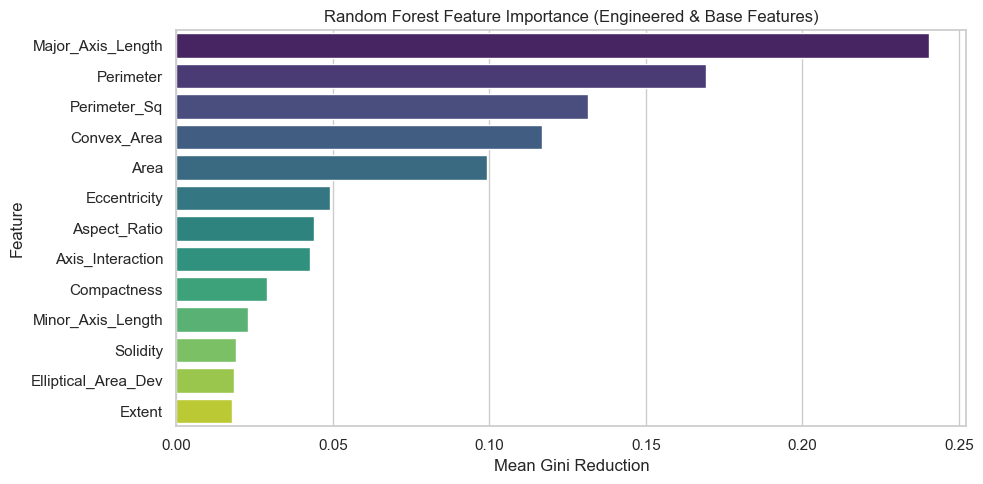

In [32]:
# --- 10.4: Embedded Feature Importance (Random Forest) ---

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_eng, y_train)

importance_df = pd.DataFrame({
    'Feature': X_train_eng.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("=" * 60)
print("FEATURE IMPORTANCE RANKING (GINI IMPURITY)")
print("=" * 60)
display(importance_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Random Forest Feature Importance (Engineered & Base Features)')
plt.xlabel('Mean Gini Reduction')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### 10.5 Dimensionality Reduction Analysis via Principal Component Analysis (PCA)
Principal Component Analysis (PCA) is an unsupervised linear transformation that projects correlated features onto an orthogonal coordinate space:
* Each subsequent Principal Component ($PC$) maximizes the remaining variance in the data.
* PCA is sensitive to scale; therefore, it must be preceded by Z-score standardization.
* We compute the **cumulative explained variance** to determine how many components are needed to retain $>95\%$ of the total information.

PCA EXPLAINED VARIANCE RATIO


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,65.4274,65.4274
1,PC2,21.5027,86.9301
2,PC3,12.7767,99.7068
3,PC4,0.1695,99.8763
4,PC5,0.0880,99.9643
5,PC6,0.0295,99.9938
6,PC7,0.0062,100.0000


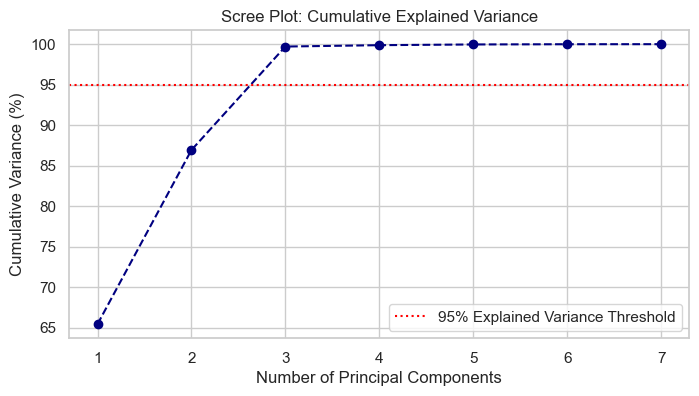

Finding: The first 3 principal components capture 99.71% of total data variance.


In [33]:
# --- 10.5: Principal Component Analysis (PCA) ---

scaler_for_pca = StandardScaler().fit(X_train_raw)
X_train_pca_input = scaler_for_pca.transform(X_train_raw)

pca = PCA()
pca.fit(X_train_pca_input)

exp_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(exp_var))],
    'Explained Variance (%)': exp_var,
    'Cumulative Variance (%)': cum_var
})

print("=" * 60)
print("PCA EXPLAINED VARIANCE RATIO")
print("=" * 60)
display(pca_summary)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--', color='navy')
plt.axhline(y=95, color='red', linestyle=':', label='95% Explained Variance Threshold')
plt.title('Scree Plot: Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance (%)')
plt.legend()
plt.grid(True)
plt.show()

print(f"Finding: The first 3 principal components capture {cum_var[2]:.2f}% of total data variance.")

### 10.6 Unified End-to-End ColumnTransformer and Pipeline Assembly
To package the entire preprocessing and feature engineering workflow into a clean, reproducible, and leak-proof structure, we assemble a Scikit-Learn `Pipeline` using `FunctionTransformer` and `StandardScaler`:
1. **Feature Engineering Step:** Constructs domain ratios, shape descriptors, and interaction terms.
2. **Feature Selection Step:** Drops redundant, highly collinear attributes identified during our correlation audit.
3. **Scaling Step:** Scales all remaining numerical features using `StandardScaler`.
4. **Leakage Protection:** The pipeline encapsulates `.fit()` and `.transform()` so test data is processed using parameters learned **only** from the training set.

In [34]:
# --- 10.6: Production Preprocessing & FE Pipeline ---

# 1. Custom transformation function for pipeline integration
def full_feature_engineering_pipeline(X_df):
    df_out = construct_domain_features(X_df)
    df_out['Axis_Interaction'] = df_out['Major_Axis_Length'] * df_out['Minor_Axis_Length']

    # Drop identified redundant/multicollinear features to prevent collinearity issues
    redundant_to_drop = ['Convex_Area', 'Perimeter', 'Axis_Interaction']
    df_out = df_out.drop(columns=[c for c in redundant_to_drop if c in df_out.columns])
    return df_out

# 2. Build the unified pipeline
fe_transformer = FunctionTransformer(full_feature_engineering_pipeline)

# Build preprocessing pipeline
data_pipeline = Pipeline(steps=[
    ('feature_engineering', fe_transformer),
    ('scaler', StandardScaler())
])

# 3. Fit pipeline strictly on Training data, then transform both Train and Test partitions
X_train_processed = data_pipeline.fit_transform(X_train_raw)
X_test_processed = data_pipeline.transform(X_test_raw)

# 4. Extract and display final processed feature names
processed_feature_names = full_feature_engineering_pipeline(X_train_raw.iloc[:1]).columns.tolist()

print("=" * 60)
print("FINAL PIPELINE EXECUTION SUMMARY")
print("=" * 60)
print(f"Final Features Selected ({len(processed_feature_names)}):")
for idx, name in enumerate(processed_feature_names, 1):
    print(f"  {idx}. {name}")

print(f"\nFinal Processed Training Array Shape: {X_train_processed.shape}")
print(f"Final Processed Testing Array Shape : {X_test_processed.shape}")
print("\nFirst sample from processed training matrix:")
print(np.round(X_train_processed[0], 4))
print("\nPipeline successfully configured and ready for model training and evaluation.")

FINAL PIPELINE EXECUTION SUMMARY
Final Features Selected (9):
  1. Area
  2. Major_Axis_Length
  3. Minor_Axis_Length
  4. Eccentricity
  5. Extent
  6. Aspect_Ratio
  7. Solidity
  8. Compactness
  9. Elliptical_Area_Dev

Final Processed Training Array Shape: (3048, 9)
Final Processed Testing Array Shape : (762, 9)

First sample from processed training matrix:
[ 0.2309 -0.2732  0.9266 -0.9334  0.9097 -0.9553 -0.1606  0.934  -0.0812]

Pipeline successfully configured and ready for model training and evaluation.



### Summary of Preprocessing and Feature Engineering Decisions

| Step | Options considered | Action taken | Reason & dataset evidence |
|---|---|---|---|
| **Missing values** | Mean / median / KNN imputation / none | None needed | 0 missing values found (EDA 5.1, cell 9.1) |
| **Duplicates** | Remove / keep | Nothing to remove | 0 exact and 0 near duplicates found |
| **Outliers** | Remove / cap / keep | Retained | Outliers are natural grain variation and break no geometric rule (EDA 5.2); removing them would discard real data |
| **Encoding** | Label / one-hot encoding | Label encoding on `Class` | Binary target; `Cammeo=0`, `Osmancik=1`. All features are numerical, so no feature encoding is needed |
| **Non-tabular features** | — | Not applicable | The dataset has no text, image, date or other non-tabular features; all inputs are numeric measurements |
| **Train/test split** | Random / stratified; 80/20 / 70/15/15 | Stratified 80/20 | Preserves the 57:43 class balance in both sets; split before preprocessing to prevent leakage |
| **Class imbalance** | SMOTE / class weighting / undersampling / none | Retained natural balance | 57:43 is mild; SMOTE could add noise because the varieties overlap |
| **Feature construction** | Original features only / add shape ratios | Added Aspect Ratio, Solidity, Compactness, Elliptical Area Deviation | Describe grain shape and slenderness from existing measurements |
| **Feature selection** | Keep all / drop redundant / PCA | Dropped `Convex_Area`, `Perimeter`, `Axis_Interaction` | Each has r > 0.95 with another kept feature; PCA rejected to keep features interpretable (see 10.3 and 10.5) |
| **Feature scaling** | Standard / Min-Max / Robust | `StandardScaler` within Pipeline | Prevents large-scale attributes (`Area`) from dominating; outliers are few, so robust scaling was not required |
| **Leakage protection** | Fit on all data / train-only fitting | Train-only fitting in `Pipeline` | Scaler and feature steps are fitted only on training data, keeping the test set unseen |


## 11. Model Training and Comparison

This section trains and compares different machine learning models to classify rice grains as Cammeo or Osmancik.

In [35]:

# Member 3 - Check the data before model training

import numpy as np
import pandas as pd

required_variables = [
    'X_train_processed',
    'X_test_processed',
    'y_train',
    'y_test'
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    print("Some preprocessing variables are missing:")
    print(missing_variables)
    print("Please run the previous notebook cells first.")

else:
    print("Preprocessing data is ready.")
    print()

    print("Training data shape:", X_train_processed.shape)
    print("Testing data shape:", X_test_processed.shape)

    print("Training labels:", len(y_train))
    print("Testing labels:", len(y_test))

    print()
    print("Training class distribution:")
    print(pd.Series(y_train).value_counts().sort_index())

    print()
    print("Missing values in training data:",
          np.isnan(X_train_processed).sum())

    print("Missing values in testing data:",
          np.isnan(X_test_processed).sum())

    print()
    print("Ready for model training.")


Preprocessing data is ready.

Training data shape: (3048, 9)
Testing data shape: (762, 9)
Training labels: 3048
Testing labels: 762

Training class distribution:
Class_Encoded
0    1304
1    1744
Name: count, dtype: int64

Missing values in training data: 0
Missing values in testing data: 0

Ready for model training.


### 11.1 Logistic Regression (Baseline Model)

Logistic Regression is used as the baseline model for rice variety classification. It is a simple classification algorithm that helps us compare the performance of other models.

In [36]:

# Train Logistic Regression baseline model

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### 11.2 K-Nearest Neighbors (KNN)

KNN classifies rice grains based on the nearest similar grains in the training dataset. I used KNN to check whether distance-based classification performs better than the Logistic Regression baseline.

In [37]:

# Train KNN model

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_processed, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


### 11.3 Decision Tree

Decision Tree classifies rice grains by learning decision rules from the features. I used this model to compare a rule-based classification method with Logistic Regression and KNN.

In [38]:

# Train Decision Tree model

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


### 11.4 Random Forest

Random Forest combines multiple decision trees to make predictions. I used this model to check whether combining trees improves the classification results compared to a single Decision Tree.

In [39]:

# Train Random Forest model

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 11.5 Final Cross-Validation Model Comparison

I compared the four classification models using 5-fold stratified cross-validation. The preprocessing pipeline was fitted separately within each training fold to avoid data leakage. I used accuracy, precision, recall and F1 score to compare model performance.

In [40]:

# Step 7 - Model comparison with leakage-safe cross-validation

import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Use the same cross-validation for all models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Models to compare
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1 Score": "f1"
}

# Store corrected results
final_model_results = []

# Store complete pipelines
trained_pipelines = {}

for model_name, model in models.items():

    print("Evaluating:", model_name)

    # Combine preprocessing and classifier
    full_pipeline = Pipeline(steps=[
        ("preprocessing", clone(data_pipeline)),
        ("classifier", clone(model))
    ])

    # Cross-validation on original training features
    scores = cross_validate(
        full_pipeline,
        X_train_raw,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    # Save mean cross-validation scores
    final_model_results.append({
        "Model": model_name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1 Score": scores["test_F1 Score"].mean(),
        "Accuracy Std": scores["test_Accuracy"].std()
    })

    # Fit the pipeline on the complete training partition
    full_pipeline.fit(X_train_raw, y_train)

    trained_pipelines[model_name] = full_pipeline

    print("Completed.\n")

# Create final comparison table
final_comparison_df = pd.DataFrame(final_model_results)

# Sort by F1 Score
final_comparison_df = final_comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("LEAKAGE-SAFE MODEL COMPARISON RESULTS")
print("=" * 60)

print(final_comparison_df.round(4).to_string(index=False))

print("\nHighest cross-validation F1 Score:")
print(final_comparison_df.iloc[0]["Model"])

print("\nAll four models evaluated successfully.")


Evaluating: Logistic Regression
Completed.

Evaluating: KNN
Completed.

Evaluating: Decision Tree
Completed.

Evaluating: Random Forest
Completed.

LEAKAGE-SAFE MODEL COMPARISON RESULTS
              Model  Accuracy  Precision  Recall  F1 Score  Accuracy Std
Logistic Regression    0.9337     0.9401  0.9444    0.9422        0.0061
      Random Forest    0.9275     0.9375  0.9358    0.9365        0.0065
                KNN    0.9236     0.9341  0.9323    0.9331        0.0068
      Decision Tree    0.9219     0.9343  0.9289    0.9315        0.0103

Highest cross-validation F1 Score:
Logistic Regression

All four models evaluated successfully.


### 11.6 Model Comparison Visualizations

I used bar charts to compare the performance of the four classification models. These graphs show the differences in accuracy, precision, recall and F1 score based on cross-validation results.

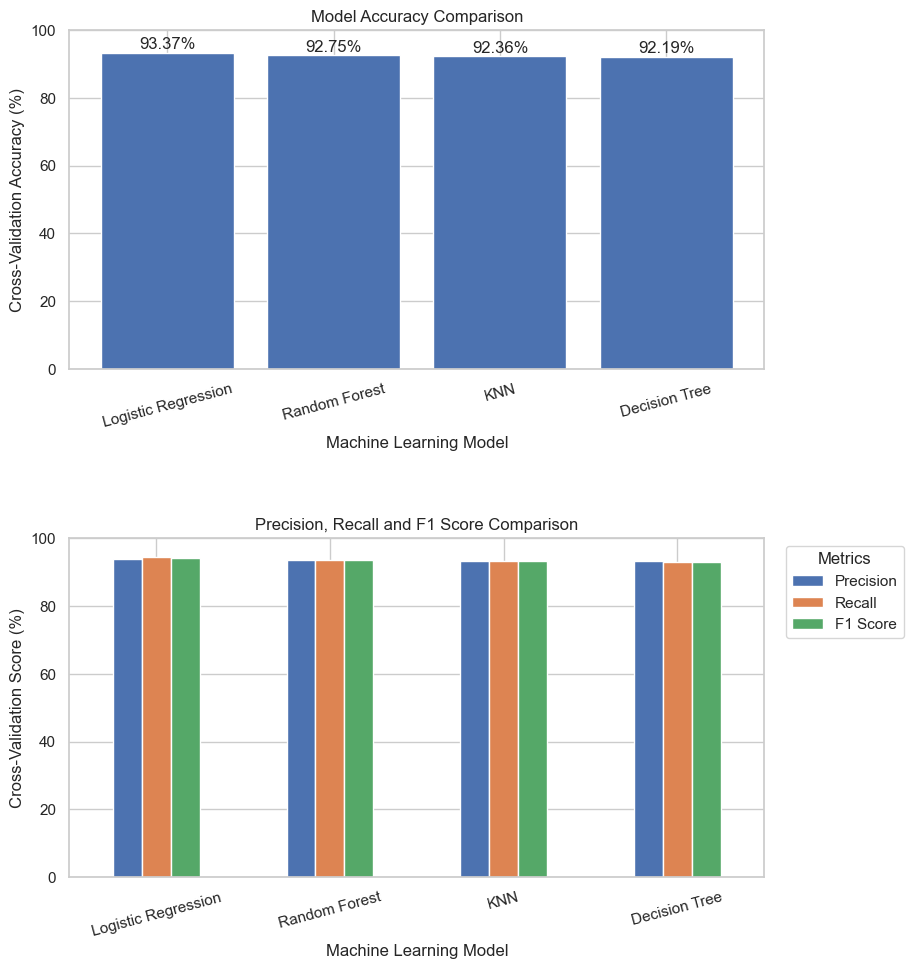

Model comparison graphs generated successfully.


In [41]:
# Step 8 - Model comparison graphs with extra space between graphs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use corrected cross-validation results
plot_df = final_comparison_df.copy()

# Create one figure with 2 graphs
fig, axes = plt.subplots(2, 1, figsize=(10, 11))

# Add vertical spacing and a bit of right margin for the legend
plt.subplots_adjust(hspace=0.5, right=0.82)

# -----------------------------
# Graph 1 - Accuracy comparison
# -----------------------------
bars = axes[0].bar(
    plot_df["Model"],
    plot_df["Accuracy"] * 100
)

axes[0].set_title("Model Accuracy Comparison")
axes[0].set_xlabel("Machine Learning Model")
axes[0].set_ylabel("Cross-Validation Accuracy (%)")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=15)

for bar in bars:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

# ------------------------------------------
# Graph 2 - Precision, Recall and F1 Score
# ------------------------------------------
metrics = ["Precision", "Recall", "F1 Score"]
comparison_plot = plot_df.set_index("Model")[metrics] * 100

comparison_plot.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Precision, Recall and F1 Score Comparison")
axes[1].set_xlabel("Machine Learning Model")
axes[1].set_ylabel("Cross-Validation Score (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=15)

axes[1].legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()

print("Model comparison graphs generated successfully.")

### 11.7 Saving Models and Comparison Results

I saved the trained models and cross-validation results so they can be used for final evaluation. Logistic Regression achieved the highest F1 score during cross-validation.

In [42]:

# Step 9 - Save trained models and comparison results

import os
import joblib

# Create folder for model outputs
output_folder = "model_outputs"
os.makedirs(output_folder, exist_ok=True)

# Save the trained pipelines
model_filenames = {
    "Logistic Regression": "logistic_regression.pkl",
    "KNN": "knn.pkl",
    "Decision Tree": "decision_tree.pkl",
    "Random Forest": "random_forest.pkl"
}

for model_name, filename in model_filenames.items():
    file_path = os.path.join(output_folder, filename)

    joblib.dump(
        trained_pipelines[model_name],
        file_path
    )

    print(model_name, "saved successfully.")

# Save the comparison results
comparison_path = os.path.join(
    output_folder,
    "model_comparison.csv"
)

final_comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nModel comparison results saved.")

# Show saved files
print("\nSaved files:")

for filename in sorted(os.listdir(output_folder)):
    print("-", filename)

print("\nAll outputs saved successfully.")

Logistic Regression saved successfully.
KNN saved successfully.
Decision Tree saved successfully.
Random Forest saved successfully.

Model comparison results saved.

Saved files:
- decision_tree.pkl
- knn.pkl
- logistic_regression.pkl
- model_comparison.csv
- random_forest.pkl

All outputs saved successfully.



### 11.8 Model Comparison Discussion

I trained four classification models: Logistic Regression, KNN, Decision Tree and Random Forest. I used 5-fold stratified cross-validation to compare their performance using accuracy, precision, recall and F1 score.

Logistic Regression gave the best results with 93.37% accuracy and 94.22% F1 score. Random Forest came second with 92.75% accuracy. KNN achieved 92.36% accuracy, while Decision Tree achieved 92.19%.

**Note on F1:** the F1, precision and recall values in this table are calculated for the positive class, Osmancik (encoded as 1). Section 12 uses **macro F1**, the average of the F1 scores for both varieties, which treats Cammeo and Osmancik equally. That is why Section 12 reports a lower value (0.9323) for the same model.

Logistic Regression performed slightly better than the other models even though it is a simpler model. Model selection is based on these cross-validation results, not on the test set. The test set is used only once, in Section 12, to evaluate the selected model.



### 11.9 Model Training Decision Log

| Decision | Options considered | Choice | Reason / evidence |
|---|---|---|---|
| Baseline model | Majority-class guess / Logistic Regression | Logistic Regression | Simple, interpretable reference point; the majority-class accuracy (57.2%) is reported in EDA 5.3 as the minimum to beat |
| Alternative 1 | KNN / SVM | KNN | Tests a distance-based method; features are already scaled in the pipeline |
| Alternative 2 | Decision Tree / Naive Bayes | Decision Tree | Tests a rule-based method that is easy to explain to QC staff |
| Alternative 3 | Random Forest / Gradient Boosting | Random Forest | Tests whether combining many trees improves on a single tree |
| Validation method | Single train/validation split / 5-fold stratified CV | 5-fold stratified CV | More reliable estimate on 3,048 training rows; keeps the 57:43 class proportions in every fold |
| Leakage control | Scale once before CV / scale inside each fold | Pipeline fitted inside each fold | Prevents train–test contamination (Lecture 3) |
| Metrics | Accuracy only / accuracy, precision, recall, F1 | Accuracy, precision, recall, F1 | Accuracy alone can mislead with uneven classes (Lecture 4) |
| Leading candidate | Highest CV score / highest test score | Highest CV score (Logistic Regression) | Choosing by test score would leak test information into model selection |

The test dataset was not used during model comparison. It is reserved for final evaluation.


In [43]:

# Step 11 - Download model outputs (Colab only)

import os
import shutil

output_folder = "model_outputs"

if os.path.exists(output_folder):
    zip_path = shutil.make_archive(
        "GrainSense_Member3_Models",
        "zip",
        root_dir=".",
        base_dir=output_folder
    )

    print("ZIP file created.")
    print("\nFiles included:")

    for filename in sorted(os.listdir(output_folder)):
        print("-", filename)

    try:
        from google.colab import files
        files.download(zip_path)
    except ImportError:
        print(f"\nNot running in Colab. ZIP saved at: {zip_path}")

else:
    print("Model outputs folder not found. Run Step 9 again.")

ZIP file created.

Files included:
- decision_tree.pkl
- knn.pkl
- logistic_regression.pkl
- model_comparison.csv
- random_forest.pkl

Not running in Colab. ZIP saved at: C:\Users\Janidu\Desktop\work space\ML project\GrainSense_Member3_Models.zip


### 11.10 Model Training Verification

I checked whether all four trained models and their saved files are working correctly. I also tested the prediction process using a few training samples before passing the models for final evaluation.

In [44]:

# Step 12 - Verify trained models and saved files

import os
import numpy as np
import pandas as pd

# Check required output files
output_folder = "model_outputs"

required_files = [
    "logistic_regression.pkl",
    "knn.pkl",
    "decision_tree.pkl",
    "random_forest.pkl",
    "model_comparison.csv"
]

print("Checking saved files:\n")

all_files_found = True

for filename in required_files:
    file_path = os.path.join(output_folder, filename)

    if os.path.isfile(file_path):
        print("[OK]", filename)
    else:
        print("[MISSING]", filename)
        all_files_found = False

# Check all trained models
print("\nChecking trained models:\n")

required_models = [
    "Logistic Regression",
    "KNN",
    "Decision Tree",
    "Random Forest"
]

all_models_found = all(
    name in trained_pipelines
    for name in required_models
)

if all_models_found:

    # Select five original training samples
    sample_data = X_train_raw.iloc[:5] if hasattr(
        X_train_raw, "iloc"
    ) else X_train_raw[:5]

    for model_name in required_models:

        model = trained_pipelines[model_name]

        predictions = model.predict(sample_data)

        print(model_name)
        print("Predictions:", predictions)
        print()

else:
    print("Some trained models are missing.")

# Final status
if all_files_found and all_models_found:
    print("All model files and predictions verified successfully.")
else:
    print("Verification incomplete. Check the missing items.")


Checking saved files:

[OK] logistic_regression.pkl
[OK] knn.pkl
[OK] decision_tree.pkl
[OK] random_forest.pkl
[OK] model_comparison.csv

Checking trained models:

Logistic Regression
Predictions: [1 0 1 0 0]

KNN
Predictions: [1 0 1 1 0]

Decision Tree
Predictions: [1 0 1 1 0]

Random Forest
Predictions: [1 0 1 1 0]

All model files and predictions verified successfully.


### 11.11 Saved Model Verification

I loaded the saved model files and checked whether they could make predictions correctly. This was done to confirm that the saved models can be used for final evaluation.

In [45]:

# Step 13 - Verify saved models

import os
import joblib
import numpy as np
import pandas as pd

output_folder = "model_outputs"

model_filenames = {
    "Logistic Regression": "logistic_regression.pkl",
    "KNN": "knn.pkl",
    "Decision Tree": "decision_tree.pkl",
    "Random Forest": "random_forest.pkl"
}

# Use five original training samples
sample_data = X_train_raw.iloc[:5] if hasattr(
    X_train_raw, "iloc"
) else X_train_raw[:5]

print("Checking saved models:\n")

for model_name, filename in model_filenames.items():

    # Load model from file
    model_path = os.path.join(output_folder, filename)
    loaded_model = joblib.load(model_path)

    # Predict using loaded model
    loaded_predictions = loaded_model.predict(sample_data)

    # Compare with the model in memory
    original_predictions = trained_pipelines[
        model_name
    ].predict(sample_data)

    predictions_match = np.array_equal(
        loaded_predictions,
        original_predictions
    )

    print(model_name)
    print("Loaded predictions:", loaded_predictions)
    print("Predictions match:", predictions_match)
    print()

# Check saved comparison table
comparison_path = os.path.join(
    output_folder,
    "model_comparison.csv"
)

saved_results = pd.read_csv(comparison_path)

print("Saved comparison results:")
print(saved_results.round(4).to_string(index=False))

print("\nSaved model verification completed.")


Checking saved models:

Logistic Regression
Loaded predictions: [1 0 1 0 0]
Predictions match: True

KNN
Loaded predictions: [1 0 1 1 0]
Predictions match: True

Decision Tree
Loaded predictions: [1 0 1 1 0]
Predictions match: True

Random Forest
Loaded predictions: [1 0 1 1 0]
Predictions match: True

Saved comparison results:
              Model  Accuracy  Precision  Recall  F1 Score  Accuracy Std
Logistic Regression    0.9337     0.9401  0.9444    0.9422        0.0061
      Random Forest    0.9275     0.9375  0.9358    0.9365        0.0065
                KNN    0.9236     0.9341  0.9323    0.9331        0.0068
      Decision Tree    0.9219     0.9343  0.9289    0.9315        0.0103

Saved model verification completed.


## 12. Model Evaluation and Final Selection

#### 12.1 Check that models and data are ready






In [46]:
required_variables = [
    "trained_pipelines",
    "final_comparison_df",
    "X_train_raw",
    "X_test_raw",
    "y_train",
    "y_test",
    "label_encoder"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run the earlier notebook cells first."
    )

print("Models available:")
for model_name in trained_pipelines:
    print("-", model_name)

print("\nTraining data:", X_train_raw.shape)
print("Testing data:", X_test_raw.shape)

print("\nClass labels:")
for number, name in enumerate(label_encoder.classes_):
    print(f"{number} = {name}")

print("\nMember 3's existing cross-validation results:")
display(final_comparison_df.round(4))

print("\nReady for Member 4 evaluation.")

Models available:
- Logistic Regression
- KNN
- Decision Tree
- Random Forest

Training data: (3048, 7)
Testing data: (762, 7)

Class labels:
0 = Cammeo
1 = Osmancik

Member 3's existing cross-validation results:


,Model,Accuracy,Precision,Recall,F1 Score,Accuracy Std
0,Logistic Regression,0.9337,0.9401,0.9444,0.9422,0.0061
1,Random Forest,0.9275,0.9375,0.9358,0.9365,0.0065
2,KNN,0.9236,0.9341,0.9323,0.9331,0.0068
3,Decision Tree,0.9219,0.9343,0.9289,0.9315,0.0103



Ready for Member 4 evaluation.


#### 12.2a Cross-Validation for Final Model Selection

In [47]:
# computed in 12.2a

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

member4_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

member4_scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy"
}

member4_results = []
member4_fold_results = []

for model_name, pipeline in trained_pipelines.items():
    print("Evaluating:", model_name)

    scores = cross_validate(
        estimator=clone(pipeline),
        X=X_train_raw,
        y=y_train,
        cv=member4_cv,
        scoring=member4_scoring,
        n_jobs=1,
        error_score="raise"
    )

    member4_results.append({
        "Model": model_name,
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 Std": scores["test_macro_f1"].std(),
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Balanced Accuracy":
            scores["test_balanced_accuracy"].mean()
    })

    for fold in range(member4_cv.n_splits):
        member4_fold_results.append({
            "Model": model_name,
            "Fold": fold + 1,
            "Macro F1": scores["test_macro_f1"][fold],
            "Accuracy": scores["test_accuracy"][fold],
            "Balanced Accuracy":
                scores["test_balanced_accuracy"][fold]
        })

member4_comparison = (
    pd.DataFrame(member4_results)
    .sort_values("Mean Macro F1", ascending=False)
    .reset_index(drop=True)
)

member4_fold_scores = pd.DataFrame(member4_fold_results)

print("\nCross-validation comparison:")
display(member4_comparison.round(4))

Evaluating: Logistic Regression
Evaluating: KNN
Evaluating: Decision Tree
Evaluating: Random Forest

Cross-validation comparison:


,Model,Mean Macro F1,Macro F1 Std,Mean Accuracy,Accuracy Std,Mean Balanced Accuracy
0,Logistic Regression,0.9323,0.0061,0.9337,0.0061,0.9319
1,Random Forest,0.9260,0.0065,0.9275,0.0065,0.9261
2,KNN,0.9219,0.0068,0.9236,0.0068,0.9221
3,Decision Tree,0.9203,0.0103,0.9219,0.0103,0.9207


**Observations — Cross-validation**

- Logistic Regression has the highest mean macro F1 (0.9323), followed by Random Forest (0.9260), KNN (0.9219) and Decision Tree (0.9203).
- The spread between the four models is small (about 0.012 macro F1). The fold standard deviations (0.0061 to 0.0103) are of a similar size, so the ranking is only a modest signal.
- Decision Tree is the least stable model (largest standard deviation, 0.0103); Logistic Regression is the most stable (0.0061).
- The following comparison describes score differences and folds won, tied or lost. It does not establish statistical significance.

#### 12.2b Fold-wise comparison chart

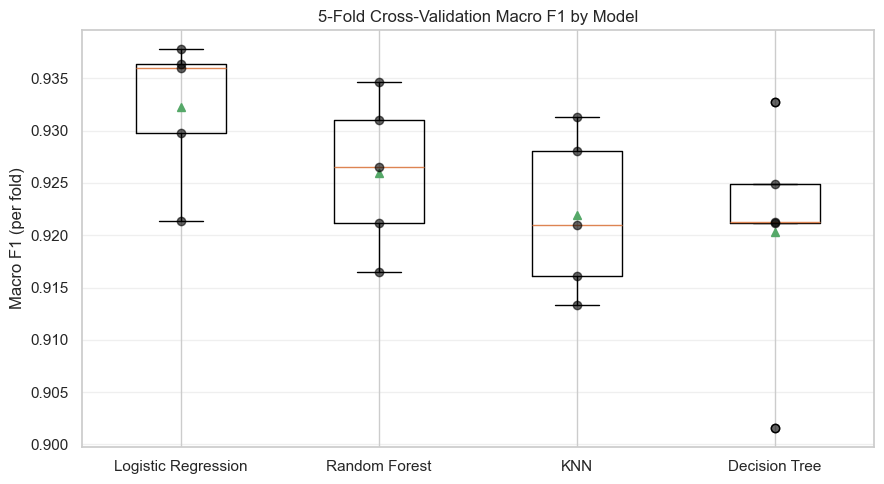

Fold-wise macro F1:


Model,Logistic Regression,Random Forest,KNN,Decision Tree
Fold,,,,
1,0.9378,0.9212,0.9161,0.9249
2,0.9364,0.9346,0.9313,0.9212
3,0.9298,0.9265,0.9280,0.9213
4,0.9214,0.9165,0.9133,0.9016
5,0.9360,0.9310,0.9210,0.9328


In [48]:
# 12.2b Fold-wise comparison chart (uses the fold scores computed in 12.2a)

import matplotlib.pyplot as plt

model_order = member4_comparison["Model"].tolist()

fold_pivot = (
    member4_fold_scores
    .pivot(index="Fold", columns="Model", values="Macro F1")
    [model_order]
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [fold_pivot[m] for m in model_order],
    labels=model_order,
    showmeans=True
)

# Show each fold as a point so the small sample (5 folds) is visible
for position, model_name in enumerate(model_order, start=1):
    ax.scatter(
        [position] * len(fold_pivot),
        fold_pivot[model_name],
        color="black",
        alpha=0.6,
        zorder=3
    )

ax.set_ylabel("Macro F1 (per fold)")
ax.set_title("5-Fold Cross-Validation Macro F1 by Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Fold-wise macro F1:")
display(fold_pivot.round(4))

**Observation:**    
 Logistic Regression had the highest mean macro F1 and the lowest observed variation across the five folds. Decision Tree showed the greatest variation.

#### 12.2c Descriptive Fold-wise Comparison.

In [49]:
# 12.2c Descriptive comparison using the same validation folds
# This replaces the paired t-test.
# No statistical-significance claims are made.

import pandas as pd

# Highest mean cross-validation macro F1
best_name = member4_comparison.iloc[0]["Model"]

# Arrange existing fold scores by model
fold_pivot = member4_fold_scores.pivot(
    index="Fold",
    columns="Model",
    values="Macro F1"
).sort_index()

paired_rows = []

for other_name in member4_comparison["Model"]:
    if other_name == best_name:
        continue

    # Compare the two models within each matching fold
    differences = fold_pivot[best_name] - fold_pivot[other_name]

    paired_rows.append({
        "Compared with": other_name,
        "Mean Macro F1 Difference": differences.mean(),
        "Minimum Difference": differences.min(),
        "Maximum Difference": differences.max(),
        "Folds Won": int((differences > 0).sum()),
        "Folds Tied": int((differences == 0).sum()),
        "Folds Lost": int((differences < 0).sum())
    })

paired_df = pd.DataFrame(paired_rows)

print("DESCRIPTIVE FOLD-WISE MODEL COMPARISON")
print("Reference model:", best_name)
print("Number of folds:", len(fold_pivot))

print("\nMacro F1 for each fold:")
display(fold_pivot.round(4))

print("\nComparison against the reference model:")
display(paired_df.round(4))

print("\nInterpretation:")

for row in paired_rows:
    print(
        f"- Compared with {row['Compared with']}, "
        f"{best_name} has a mean macro F1 difference of "
        f"{row['Mean Macro F1 Difference']:.4f}; "
        f"wins {row['Folds Won']}, "
        f"ties {row['Folds Tied']}, "
        f"and loses {row['Folds Lost']} folds."
    )

print(
    "\nA positive difference favours the reference model. "
    "A negative difference favours the comparison model."
)

print(
    "\nLimitation: cross-validation training folds overlap, "
    "so these fold scores are not independent. "
    "These results describe the observed differences; "
    "they do not establish statistical superiority."
)

print(
    "\nModel selection remains based on mean cross-validation "
    "macro F1, with variation across folds and simplicity "
    "considered when interpreting close results. "
    "No test data is used in this comparison."
)

DESCRIPTIVE FOLD-WISE MODEL COMPARISON
Reference model: Logistic Regression
Number of folds: 5

Macro F1 for each fold:


Model,Decision Tree,KNN,Logistic Regression,Random Forest
Fold,,,,
1,0.9249,0.9161,0.9378,0.9212
2,0.9212,0.9313,0.9364,0.9346
3,0.9213,0.9280,0.9298,0.9265
4,0.9016,0.9133,0.9214,0.9165
5,0.9328,0.9210,0.9360,0.9310



Comparison against the reference model:


,Compared with,Mean Macro F1 Difference,Minimum Difference,Maximum Difference,Folds Won,Folds Tied,Folds Lost
0,Random Forest,0.0063,0.0018,0.0166,5,0,0
1,KNN,0.0103,0.0018,0.0216,5,0,0
2,Decision Tree,0.0119,0.0032,0.0198,5,0,0



Interpretation:
- Compared with Random Forest, Logistic Regression has a mean macro F1 difference of 0.0063; wins 5, ties 0, and loses 0 folds.
- Compared with KNN, Logistic Regression has a mean macro F1 difference of 0.0103; wins 5, ties 0, and loses 0 folds.
- Compared with Decision Tree, Logistic Regression has a mean macro F1 difference of 0.0119; wins 5, ties 0, and loses 0 folds.

A positive difference favours the reference model. A negative difference favours the comparison model.

Limitation: cross-validation training folds overlap, so these fold scores are not independent. These results describe the observed differences; they do not establish statistical superiority.

Model selection remains based on mean cross-validation macro F1, with variation across folds and simplicity considered when interpreting close results. No test data is used in this comparison.


**Observation:**  
Logistic Regression scored higher than each alternative in all five folds. These descriptive results support its selection but do not establish statistical superiority.

#### 12.3 Final Model Selection

In [50]:
# 12.3 Record the selected model before test evaluation

from sklearn.base import clone

# Select using the highest mean cross-validation macro F1
selected_model_name = member4_comparison.iloc[0]["Model"]

# Copy the selected configuration and fit on all training data
final_model = clone(trained_pipelines[selected_model_name])
final_model.fit(X_train_raw, y_train)

# Record the selection evidence
selection_record = member4_comparison.iloc[[0]].copy()
selection_record["Selection Metric"] = "Mean CV Macro F1"
selection_record["Prediction Rule"] = "Default classifier.predict()"

print("Selected model:", selected_model_name)

print("\nSelection evidence:")
display(selection_record.round(4))

print("\nClassifier settings:")
print(final_model.named_steps["classifier"].get_params())

print("\nFinal model fitted on training data.")
print("No test predictions were made in this cell.")

Selected model: Logistic Regression

Selection evidence:


,Model,Mean Macro F1,Macro F1 Std,Mean Accuracy,Accuracy Std,Mean Balanced Accuracy,Selection Metric,Prediction Rule
0,Logistic Regression,0.9323,0.0061,0.9337,0.0061,0.9319,Mean CV Macro F1,Default classifier.predict()



Classifier settings:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Final model fitted on training data.
No test predictions were made in this cell.


**Observation:**  
Logistic Regression was selected because it achieved the highest mean cross-validation macro F1 (0.9323), with a standard deviation of 0.0061. Selection was based on training-data validation.

#### 12.4 Test-Set Evaluation

In [51]:
# 12.4 Evaluate the selected model on the test partition

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Predict once; reuse these predictions in later evaluation cells
y_test_pred = final_model.predict(X_test_raw)

# Overall performance
test_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1"
    ],
    "Score": [
        accuracy_score(y_test, y_test_pred),
        balanced_accuracy_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred, average="macro"),
        f1_score(y_test, y_test_pred, average="weighted")
    ]
})

print("Test performance:", selected_model_name)
display(test_metrics.round(4))

# Verify label order and obtain the corresponding variety names
class_labels = final_model.classes_
class_names = label_encoder.inverse_transform(
    class_labels.astype(int)
)

# Detailed performance for each variety
report = classification_report(
    y_test,
    y_test_pred,
    labels=class_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_report_df = (
    pd.DataFrame(report)
    .T
    .loc[class_names, ["precision", "recall", "f1-score", "support"]]
)

class_report_df["support"] = class_report_df["support"].astype(int)

print("\nPerformance for each rice variety:")
display(class_report_df.round(4))

# Count correct and incorrect predictions
correct_predictions = int(
    (np.asarray(y_test) == y_test_pred).sum()
)
incorrect_predictions = len(y_test) - correct_predictions

print("\nTotal test grains:", len(y_test))
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)

Test performance: Logistic Regression


,Metric,Score
0,Accuracy,0.9173
1,Balanced Accuracy,0.9127
2,Macro F1,0.9150
3,Weighted F1,0.9170



Performance for each rice variety:


,precision,recall,f1-score,support
Cammeo,0.9228,0.8804,0.9011,326
Osmancik,0.9135,0.9450,0.9290,436



Total test grains: 762
Correct predictions: 699
Incorrect predictions: 63


 **Observation:**  
 The selected model correctly classified 699 of 762 test grains, achieving 91.73% accuracy and 0.9150 macro F1. Recall was higher for Osmancik (94.50%) than Cammeo (88.04%).

#### 12.5 Confusion Matrix

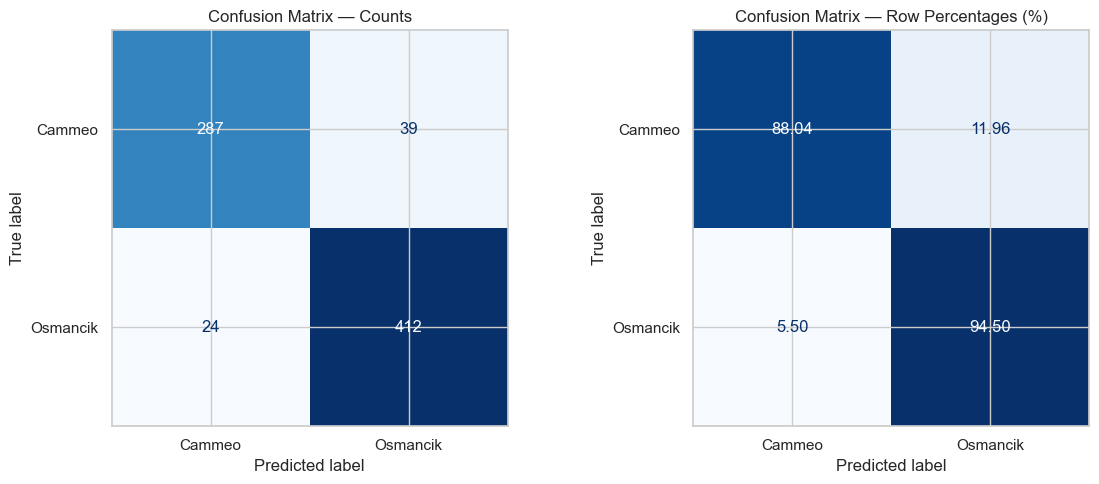

Confusion matrix counts:


Predicted,Cammeo,Osmancik
Actual,,
Cammeo,287,39
Osmancik,24,412


In [52]:
# 12.5 Visualise errors using existing test predictions

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Counts
cm_counts = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

# Fractions within each actual variety
cm_normalized = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels,
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_counts,
    display_labels=class_names
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Confusion Matrix — Counts")

ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized * 100,
    display_labels=class_names
).plot(
    ax=axes[1],
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

axes[1].set_title("Confusion Matrix — Row Percentages (%)")

plt.tight_layout()
plt.show()

# Keep tables for exporting later
cm_counts_df = pd.DataFrame(
    cm_counts,
    index=class_names,
    columns=class_names
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=class_names,
    columns=class_names
)

for table in [cm_counts_df, cm_normalized_df]:
    table.index.name = "Actual"
    table.columns.name = "Predicted"

print("Confusion matrix counts:")
display(cm_counts_df)

**Observation:**  
 The model misclassified 39 Cammeo grains as Osmancik and 24 Osmancik grains as Cammeo. Cammeo had the higher error rate: 11.96%, compared with 5.50% for Osmancik.

#### 12.6 ROC Curve and ROC-AUC

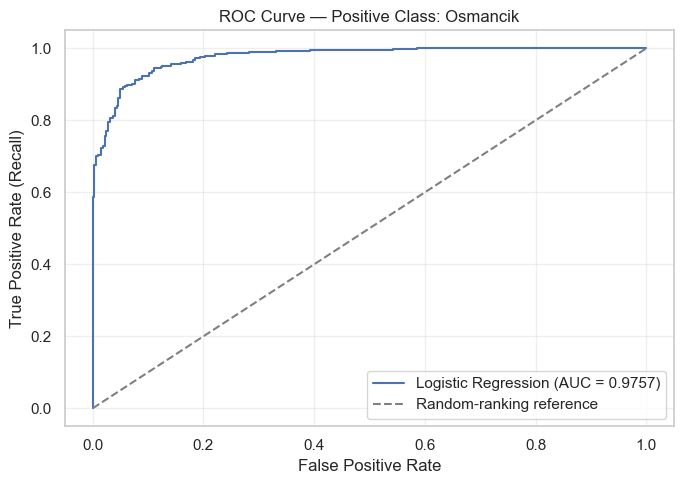

Positive class: Osmancik
Test ROC-AUC: 0.9757


In [53]:
# 12.6 ROC curve using the selected model's probability scores

from sklearn.metrics import roc_auc_score, roc_curve

# Find Osmancik's encoded label and probability column
positive_label = int(
    label_encoder.transform(["Osmancik"])[0]
)

positive_column = np.flatnonzero(
    final_model.classes_ == positive_label
).item()

# Obtain probability scores for Osmancik
y_test_probability = final_model.predict_proba(
    X_test_raw
)[:, positive_column]

# Represent Osmancik as 1 and Cammeo as 0 for this analysis
y_test_binary = (
    np.asarray(y_test) == positive_label
).astype(int)

# Calculate AUC and curve coordinates
test_roc_auc = roc_auc_score(
    y_test_binary,
    y_test_probability
)

fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_test_probability
)

# Plot the ROC curve
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {test_roc_auc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random-ranking reference"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC Curve — Positive Class: Osmancik")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Positive class: Osmancik")
print(f"Test ROC-AUC: {test_roc_auc:.4f}")

**Observation:**  
The ROC-AUC of 0.9757 indicates strong separation between the varieties on this test partition. This measures ranking performance, not classification accuracy.

#### 12.7 Error Analysis

In [54]:
# 12.7 Inspect errors using existing predictions

# Keep the original measurements and row indices
test_details = X_test_raw.copy()

# Use arrays to preserve the test-row order
test_details["Actual"] = label_encoder.inverse_transform(
    np.asarray(y_test).astype(int)
)

test_details["Predicted"] = label_encoder.inverse_transform(
    np.asarray(y_test_pred).astype(int)
)

test_details["Correct"] = (
    test_details["Actual"] == test_details["Predicted"]
)

# Extract all incorrect predictions
misclassified_grains = test_details.loc[
    ~test_details["Correct"]
].copy()

print("Total misclassified grains:", len(misclassified_grains))
print("\nFirst 10 misclassified grains:")
display(misclassified_grains.head(10))

# Calculate error rates separately for each actual variety
error_summary = (
    test_details.groupby("Actual")["Correct"]
    .agg(Total="size", Correct="sum")
)

error_summary["Errors"] = (
    error_summary["Total"] - error_summary["Correct"]
)

error_summary["Error Rate (%)"] = (
    error_summary["Errors"] / error_summary["Total"] * 100
)

print("\nError summary by actual variety:")
display(error_summary.round(2))

# Compare measurements within each actual variety
features_to_inspect = [
    "Area",
    "Major_Axis_Length",
    "Minor_Axis_Length",
    "Eccentricity"
]

test_details["Outcome"] = np.where(
    test_details["Correct"],
    "Correct",
    "Incorrect"
)

error_feature_comparison = (
    test_details
    .groupby(["Actual", "Outcome"])[features_to_inspect]
    .mean()
)

print("\nMean measurements: correct versus incorrect predictions")
display(error_feature_comparison.round(4))

Total misclassified grains: 63

First 10 misclassified grains:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Actual,Predicted,Correct
3396,13619,467.7660,193.6809,90.4735,0.8842,13926,0.5867,Osmancik,Cammeo,False
2798,12013,458.3590,195.0823,79.6427,0.9129,12330,0.6102,Osmancik,Cammeo,False
3555,12959,473.6100,206.2255,80.6336,0.9204,13309,0.5952,Osmancik,Cammeo,False
3295,12451,461.3450,191.4078,84.1615,0.8981,12833,0.5813,Osmancik,Cammeo,False
3342,15062,492.0650,198.0274,99.1107,0.8657,15584,0.7842,Osmancik,Cammeo,False
206,12162,454.7760,191.1208,82.3174,0.9025,12493,0.7452,Cammeo,Osmancik,False
492,13059,456.4410,185.9820,90.2045,0.8745,13339,0.6194,Cammeo,Osmancik,False
1321,12040,441.0230,182.7528,85.1511,0.8848,12372,0.7474,Cammeo,Osmancik,False
3561,13093,470.1000,197.1970,85.7973,0.9004,13358,0.5574,Osmancik,Cammeo,False
2985,13443,469.4540,196.6380,87.9791,0.8943,13686,0.5723,Osmancik,Cammeo,False



Error summary by actual variety:


,Total,Correct,Errors,Error Rate (%)
Actual,,,,
Cammeo,326,287,39,11.9600
Osmancik,436,412,24,5.5000



Mean measurements: correct versus incorrect predictions


Area  Major_Axis_Length  Minor_Axis_Length  \
Actual   Outcome                                                       
Cammeo   Correct   14,348.5575           207.4354            89.0681   
         Incorrect 12,124.5128           186.9598            83.5946   
Osmancik Correct   11,449.5267           175.6376            84.0659   
         Incorrect 12,968.8750           195.7800            85.4204   

                    Eccentricity  
Actual   Outcome                  
Cammeo   Correct          0.9025  
         Incorrect        0.8939  
Osmancik Correct          0.8768  
         Incorrect        0.8993

**Observation:**   
Misclassified Cammeo grains were smaller and shorter on average than correctly classified Cammeo grains, while misclassified Osmancik grains were larger and longer. These patterns suggest measurement overlap but do not prove the cause of individual errors.

#### 12.8 Supplementary Train, CV and Test Comparison




,Model,Train Macro F1,CV Macro F1,Test Macro F1,Test Accuracy,Test Balanced Accuracy,Test ROC-AUC,Train - CV gap,CV - Test gap
0,Logistic Regression,0.9333,0.9323,0.9150,0.9173,0.9127,0.9757,0.0010,0.0172
1,Random Forest,1.0000,0.9260,0.9177,0.9199,0.9153,0.9719,0.0740,0.0082
2,KNN,0.9451,0.9219,0.9115,0.9134,0.9115,0.9489,0.0231,0.0104
3,Decision Tree,0.9452,0.9203,0.9022,0.9042,0.9024,0.9450,0.0248,0.0181


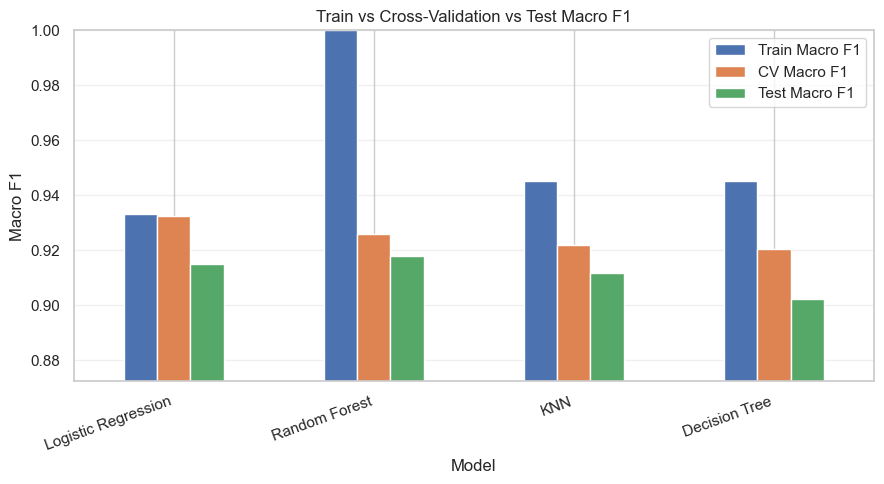

Largest train-to-CV gap: Random Forest (0.0740)
Best test macro F1: Random Forest; selected model: Logistic Regression


In [55]:
# 12.8 Confirmation on the test set for all four models + overfitting check

from sklearn.metrics import roc_auc_score

confirmation_rows = []

for model_name, pipeline in trained_pipelines.items():
    model = clone(pipeline)
    model.fit(X_train_raw, y_train)

    train_pred = model.predict(X_train_raw)
    test_pred = model.predict(X_test_raw)

    positive_col = np.flatnonzero(model.classes_ == positive_label).item()
    test_prob = model.predict_proba(X_test_raw)[:, positive_col]

    cv_macro_f1 = member4_comparison.loc[
        member4_comparison["Model"] == model_name, "Mean Macro F1"
    ].item()

    train_macro_f1 = f1_score(y_train, train_pred, average="macro")
    test_macro_f1 = f1_score(y_test, test_pred, average="macro")

    confirmation_rows.append({
        "Model": model_name,
        "Train Macro F1": train_macro_f1,
        "CV Macro F1": cv_macro_f1,
        "Test Macro F1": test_macro_f1,
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "Test ROC-AUC": roc_auc_score(
            (np.asarray(y_test) == positive_label).astype(int), test_prob
        ),
        "Train - CV gap": train_macro_f1 - cv_macro_f1,
        "CV - Test gap": cv_macro_f1 - test_macro_f1
    })

confirmation_df = (
    pd.DataFrame(confirmation_rows)
    .sort_values("CV Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(confirmation_df.round(4))

# Plot train / CV / test macro F1 side by side
plot_df = confirmation_df.set_index("Model")[
    ["Train Macro F1", "CV Macro F1", "Test Macro F1"]
]

ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("Macro F1")
ax.set_ylim(
    max(0, plot_df.values.min() - 0.03),
    min(1.0, plot_df.values.max() + 0.02)
)
ax.set_title("Train vs Cross-Validation vs Test Macro F1")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

largest = confirmation_df.loc[confirmation_df["Train - CV gap"].idxmax()]
print(f"Largest train-to-CV gap: {largest['Model']} "
      f"({largest['Train - CV gap']:.4f})")

test_best = confirmation_df.loc[confirmation_df["Test Macro F1"].idxmax(), "Model"]
print(f"Best test macro F1: {test_best}; selected model: {selected_model_name}")

**Observation:**  
   Random Forest had the largest training-to-CV macro F1 gap (0.0740), suggesting more overfitting. Although its test macro F1 was slightly higher, Logistic Regression remains selected based on cross-validation.


#### 12.9 Final Recommendation and Limitations

##### Recommendation

Logistic Regression is recommended as the final model among the four evaluated candidates. It achieved the highest mean cross-validation macro F1 (0.9323) and the lowest observed macro F1 standard deviation (0.0061).

On the test partition, it correctly classified 699 of 762 grains, achieving 91.73% accuracy, 0.9150 macro F1, 91.27% balanced accuracy and 0.9757 ROC-AUC.

##### Stakeholder value

For the rice mill, the model offers a fast and consistent way to check grain variety from image measurements, replacing slow and subjective manual visual sorting. It can flag batches whose predicted variety does not match the declared variety, so they can be checked before grading and pricing. Logistic Regression is also simple to explain to quality-control staff, which supports trust in its decisions.

##### Risks

- Cammeo had the higher error rate on the test partition: 39 of 326 Cammeo grains (11.96%) were predicted as Osmancik, compared with 24 of 436 Osmancik grains (5.50%) predicted as Cammeo. In practice, some Cammeo grains could be graded or priced as Osmancik, so the model should support, not replace, human checks for borderline batches.
- The model always returns one of the two varieties, even for a broken grain or a different variety, so unusual inputs need a manual review step.

##### Limitations

- The evaluation covers only Cammeo and Osmancik. Performance on other rice varieties has not been established.
- Variety classification does not measure overall rice quality, such as moisture content or contamination.
- Changes in imaging conditions or measurement scale may affect predictions.
- Performance on independent batches, seasons and production environments requires further validation.
- Feature choices were informed by the overall training partition before cross-validation, which may make validation results optimistic.
- The test partition had already been inspected during a provisional reference-model experiment. It is therefore not a completely untouched final assessment.
- ROC-AUC measures ranking performance; it does not establish probability calibration or deployment readiness.
  